<figure style="text-align: center;">
  <img src="_static/intro/title_page.png" style="display: block; margin: 0 auto; width: 100%;">
</figure>

### Transformers

Michael J. Pyrcz, Professor, The University of Texas at Austin 

[Twitter](https://twitter.com/geostatsguy) | [GitHub](https://github.com/GeostatsGuy) | [Website](http://michaelpyrcz.com) | [GoogleScholar](https://scholar.google.com/citations?user=QVZ20eQAAAAJ&hl=en&oi=ao) | [Geostatistics Book](https://www.amazon.com/Geostatistical-Reservoir-Modeling-Michael-Pyrcz/dp/0199731446) | [YouTube](https://www.youtube.com/channel/UCLqEr-xV-ceHdXXXrTId5ig)  | [Applied Geostats in Python e-book](https://geostatsguy.github.io/GeostatsPyDemos_Book/intro.html) | [Applied Machine Learning in Python e-book](https://geostatsguy.github.io/MachineLearningDemos_Book/) | [LinkedIn](https://www.linkedin.com/in/michael-pyrcz-61a648a1)

Chapter of e-book "Applied Machine Learning in Python: a Hands-on Guide with Code". 

```{admonition} Cite this e-Book as:
:class: remove-from-content-only

Pyrcz, M.J., 2024, *Applied Machine Learning in Python: A Hands-on Guide with Code* [e-book]. Zenodo. doi:10.5281/zenodo.15169139 [![DOI](https://zenodo.org/badge/863274676.svg)](https://doi.org/10.5281/zenodo.15169139) 
```

The workflows in this book and more are available here:

```{admonition} Cite the MachineLearningDemos GitHub Repository as:
:class: remove-from-content-only

Pyrcz, M.J., 2024, *MachineLearningDemos: Python Machine Learning Demonstration Workflows Repository* (0.0.3) [Software]. Zenodo. DOI: 10.5281/zenodo.13835312. GitHub repository: https://github.com/GeostatsGuy/MachineLearningDemos [![DOI](https://zenodo.org/badge/862519860.svg)](https://zenodo.org/doi/10.5281/zenodo.13835312)
```

By Michael J. Pyrcz <br />
&copy; Copyright 2024.

This chapter is a tutorial for / demonstration of **Transformers**. 

**YouTube Lecture**: check out my lectures on:

* [Artificial Neural Networks](https://youtu.be/A9PiCMY_6nM?si=NxWSU_5RgQ4w55EL)
* [Convolutional Neural Networks](https://youtu.be/za2my_XDoOs?si=LeHU6p2_fc9dX4Yt)

These lectures are all part of my [Machine Learning Course](https://youtube.com/playlist?list=PLG19vXLQHvSC2ZKFIkgVpI9fCjkN38kwf&si=XonjO2wHdXffMpeI) on YouTube with linked well-documented Python workflows and interactive dashboards. My goal is to share accessible, actionable, and repeatable educational content. If you want to know about my motivation, check out [Michael's Story](https://michaelpyrcz.com/my-story). 


#### Motivation

We have developed a progression from probability and statistics through inferential and predictive methods, including artificial neural networks (ANNs), convolutional neural networks (CNNs), generative adversarial networks (GANs), autoencoders (AEs), recurrent neural networks (RNNs), and long short-term memory networks (LSTMs). We have also introduced the attention mechanism, with two intutivie interactive demonstrations to help develop an understanding of how attention works.

We are now ready to introduce **transformers**, a neural network architecture that uses attention to learn relationships between different positions in a sequence.


#### From LSTMs to Transformers

Our LSTM model processes a sequence by updating its cell state and hidden state at each time step. Information is carried forward through the sequence, allowing the model to learn temporal relationships and make predictions.

Transformers approach sequence modeling differently. Rather than relying on recurrent updates to carry information from one time step to the next, transformers use **self-attention** to learn relationships between positions in the input sequence. This allows a model to directly relate information from different positions, including positions that are far apart.


#### What We Will Learn

We will introduce the key components of a transformer architecture:

* **Input representations and positional information** - represent the input data and provide information about the position or ordering of each observation in the sequence.

* **Query, key, and value vectors** - transform the input representations into vectors used to calculate attention weights and combine information.

* **Self-attention** - calculate attention weights that determine how information from different positions contributes to each output representation.

* **Multi-head attention** - use multiple attention mechanisms to learn different relationships within the input sequence.

* **Feed-forward networks** - further transform the representations produced by the attention mechanism.

* **Residual connections and layer normalization** - support information flow and help stabilize neural network training.

* **Attention masking** - restrict which positions can contribute to a representation when required, such as preventing a prediction from using future observations.

* **Transformer architectures** - distinguish encoder-only, encoder-decoder, and decoder-only models and understand their different applications.


#### Self-Attention

The central mathematical operation in a transformer is scaled dot-product attention:

$$
\operatorname{Attention}(Q,K,V) = \operatorname{softmax} \left( \frac{QK^\top}{\sqrt{d_k}} \right)V
$$

where:
* $Q$ is the matrix of query vectors.
* $K$ is the matrix of key vectors.
* $V$ is the matrix of value vectors.
* $d_k$ is the dimension of the key vectors.
* $QK^\top$ calculates similarity scores between queries and keys.
* $\sqrt{d_k}$ scales the similarity scores.
* $\operatorname{softmax}(\cdot)$ converts the scores into normalized attention weights.
* Multiplication by $V$ calculates weighted combinations of the value vectors.

The critical difference between self-attention and the general attention mechanism is that the resulting representations incorporate information from other positions in the sequence, with the contribution of each position determined by the attention weights.


#### Application to Subsurface Prediction

We use a subsurface prediction problem to connect the transformer architecture to our previous work. For example, we can predict permeability along a depth sequence and investigate how the model uses information from different depth intervals.

We can visualize the attention weights to examine which positions contribute to the representations calculated by the model. We can also compare the transformer with our LSTM model using the same training and forecast intervals.

This comparison will help us understand the differences between recurrent sequence modeling and attention-based sequence modeling. It is important to remember that attention weights are not necessarily measures of geological importance or causal influence, and transformers are not guaranteed to outperform LSTMs, particularly when training data are limited.

By building on our previous work with neural networks, LSTMs, and attention, we can develop an understanding of how transformers learn relationships within sequences and use those relationships to make predictions.




#### Simple Transformer Architecture

This is our simple transformer architecture.

We will proceed through the following steps:

* **Identify the main components**: Introduce the different parts of our Transformer architecture.

* **Walk through the architecture**: Examine each component step-by-step, explaining the information flow and the underlying mathematics.

* **Build it from scratch**: Implement our Transformer using NumPy and basic mathematical operations, without deep learning libraries.

* **Train and demonstrate**: Train our Transformer on a simple synthetic dataset and examine its predictions and learned attention weights.

* **Scale up the application**: Train and demonstrate our Transformer using a more complicated dataset containing 100 synthetic well logs.

Here's a flowchart of our simple transformer.

<figure style="text-align: center;">
  <img src="_static/transformer/transformer_flow.png" style="display: block; margin: 0 auto; width: 80%;">
  <figcaption style="text-align: center;"> Simple transformer flow chart.
</figcaption>
</figure>

The novel aspects of a transformer are,

* **Embeddings** – efficient representations of input values and their positions in the sequence.

* **Query, Key, and Value** – what information are we looking for (Query), what information is available (Key), and what information can be shared (Value)?

* **Attention** – evaluates relationships between all combinations of queries and keys, allowing information to be gathered from across the sequence.

* **Feed-forward neural network** – learns additional transformations of the representations at each position, using the information integrated through attention.

<figure style="text-align: center;">
  <img src="_static/transformer/transformer_flow_parts.png" style="display: block; margin: 0 auto; width: 100%;">
  <figcaption style="text-align: center;"> Simple transformer flow chart with parts labelled.
</figcaption>
</figure>

#### Input Embeddings

Input embeddings are learned representations of the predictor feature(s), 

* transform the predictor feature, porosity, into a vector representation of dimension $d_{model}$
  
* in our model, we use a linear layer transformation,

$$
e_t = W_e x_t + b_e
$$

where,

$W_e$ are the learnable embedding weights
$b_e$ are the learnable embedding biases
$e_t$ are the input embeddings representation at depth 𝑡, 

<figure style="text-align: center;">
  <img src="_static/transformer/transformer_flow_input_embeddings.png" style="display: block; margin: 0 auto; width: 100%;">
  <figcaption style="text-align: center;"> Simple transformer flow chart with input embeddings.
</figcaption>
</figure>

given our model dimension of $d_{model} = 4$,

* input embeddings in matrix notation

$$
\begin{bmatrix} e_{t,1} \\ e_{t,2} \\ e_{t,3} \\ e_{t,4} \end{bmatrix} =
\begin{bmatrix} W_{e,1} \\ W_{e,2} \\ W_{e,3} \\ W_{e,4} \end{bmatrix} x_t +
\begin{bmatrix} b_{e,1} \\ b_{e,2} \\ b_{e,3} \\ b_{e,4} \end{bmatrix} 
$$

* input embeddings illustrated

<figure style="text-align: center;">
  <img src="_static/transformer/input_embeddings.png" style="display: block; margin: 0 auto; width: 40%;">
  <figcaption style="text-align: center;"> Input embeddings from input predictor feature to vector of input embeddings.
</figcaption>
</figure>

Above we specify a simple trainable linear projection for our input embeddings. Here is a sumamry of commonly applied types of input embeddings:

1. Linear Projection

* linear network for transforming input features into an embedding vector. (we use this)

2. Artificial Neural Networks (ANNs)

* nonlinear mapping from normalized predictor features to an input embedding vector.

* includes nonlinear activation functions in hidden layer(s)

<figure style="text-align: center;">
  <img src="_static/transformer/input_embeddings_nn.png" style="display: block; margin: 0 auto; width: 40%;">
  <figcaption style="text-align: center;"> Input embeddings from input predictor feature to vector of input embeddings via artificial neural network.
</figcaption>
</figure>

3. Fourier Feature Embeddings

* transform input features using sinusoidal functions at multiple frequencies:

$$
e_t = \left[ sin(\omega_1 x_t ), cos( \omega_1 x_t ), \ldots \right]
$$

$\quad$ where, 

* wavelengths, $\omega_1, \omega_2, \omega_3, \ldots$ to represent patterns at different scales.


#### Positional Embeddings

Positional embeddings provide information about the locations of observations in the input sequence, including training and prediction locations.

Fixed sinusoidal positional encodings:

* deterministic vectors of sine and cosine values at different frequencies.

* no trainable positional parameters.

* can represent positions beyond those seen during training, subject to implementation and model behavior.

<figure style="text-align: center;">
  <img src="_static/transformer/transformer_flow_positional_embeddings.png" style="display: block; margin: 0 auto; width: 100%;">
  <figcaption style="text-align: center;"> Simple transformer flow chart with input and positional embeddings.
</figcaption>
</figure>

The positional encoding at location 𝑡 is:

$$
p_{t_{odd}} = sin⁡ \left( \frac{2 \pi}{ \lambda t} \right)                    
$$

$$
p_{t_{even}} = cos⁡ \left( \frac{2 \pi}{ \lambda t} \right)                    
$$

where $t$ is the coordinate and $\lambda$ is the wavelength.

Multiscale representation:

* multiple wavelengths represent spatial patterns at different scales.

* sine and cosine functions provide two complementary components for each wavelength.

  
The positional encoding dimension $𝑛_{p_t} = 2 |\lambda |$, 

where $| \lambda |$ is number of wavelengths


#### Combined Embeddings

Combine the input embedding and positional encoding through element-wise addition, 

* bringing together information about what the input is and where it occurs in the sequence.

$$
z_t = e_t + p_t
$$

where,

* $e_t \in \mathbb{R}^{d_{model}}$ is the input embedding and $p_t \in \mathbb{R}^{d_{model}}$ is the positional encoding at position $t$.

* the resulting combined embedding, $z_t$, is passed to the self-attention layer. 

* both vectors must have the same dimension to allow element-wise addition.

<figure style="text-align: center;">
  <img src="_static/transformer/transformer_flow_combined_embeddings.png" style="display: block; margin: 0 auto; width: 100%;">
  <figcaption style="text-align: center;"> Simple transformer flow chart with input, positional embeddings and combined embeddings.
</figcaption>
</figure>

given our model dimension of $d_{model} = 4$,

* input $e_t$, positional $p_t$ and combined embeddings $z_t$ in matrix notation,

$$
\begin{bmatrix} z_{t,1} \\ z_{t,2} \\ z_{t,3} \\ z_{t,4} \end{bmatrix} =
\begin{bmatrix} e_{t,1} \\ e_{t,2} \\ e_{t,3} \\ e_{t,4} \end{bmatrix} +
\begin{bmatrix} p_{t,1} \\ p_{t,2} \\ p_{t,3} \\ p_{t,4} \end{bmatrix} =
\begin{bmatrix} e_{t,1}+p_{t,1} \\ e_{t,2}+p_{t,2} \\ e_{t,3}+p_{t,3} \\ e_{t,4}+p_{t,4} \end{bmatrix}
$$

and here is an illustration of input, positional and combined embeddings.

<figure style="text-align: center;">
  <img src="_static/transformer/combined_embeddings.png" style="display: block; margin: 0 auto; width: 100%;">
  <figcaption style="text-align: center;"> Visual example of combined embedding from input and positional embeddings.
</figcaption>
</figure>


#### Query, Key and Values

Attention mechanism is covered in the attention mechanism chapter of this e-book. Here's a recall of query, key and values,

<figure style="text-align: center;">
  <img src="_static/transformer/transformer_flow_qkv.png" style="display: block; margin: 0 auto; width: 100%;">
  <figcaption style="text-align: center;"> Simple transformer flow chart with input, positional embeddings and combined embeddings, and query, key and value.
</figcaption>
</figure>

* **Query (Q)** - query vector represents the current pattern we are trying to match against information from other positions in the sequence

$$
Q_{1 \times d} = \begin{bmatrix} q_1 & q_2 & \cdots & q_d \end{bmatrix}
$$

$\quad$ where,
- $d$ = number of features in the query pattern, typically $d_{model} \times d_{model}$

* **Keys (K)** - key matrix contains representations of all candidate positions in the sequence. Queries are compared against Keys to determine how relevant each position is.

$$
K_{N \times d} = \begin{bmatrix} k_{1,1} & k_{1,2} & \cdots & k_{1,d} \\ k_{2,1} & k_{2,2} & \cdots & k_{2,d} \\ \vdots & \vdots & \ddots & \vdots \\
k_{N,1} & k_{N,2} & \cdots & k_{N,d} \end{bmatrix}
$$

$\quad$ where,
- $N$ is number of stored analogs

* **Values (V)** - value matrix contains the information associated with each position. The Values are weighted by the attention weights and combined to produce the attention output.

$$
\mathbf{V}_{N \times 1} = \begin{bmatrix} v_1 \\ v_2 \\ \vdots \\ v_N \end{bmatrix}
$$

$\quad$ where, 
- $v_i$ is associated with $i^{th}$ key, $v_i$ may be a scalar, vector, or even a dictionary

This is a trainable projection of combined embedding, $z_t$, to, 

* Query ($Q_t$), Key ($K_t$) and Value ($V_t$), using trainable parameters.

* For our example, use linear projections,

$$
Q_t = W_Q z_t + b_Q       
$$

$$
K_t = W_K z_t + b_K
$$

$$
V_t = W_V z_t + b_V
$$

Each projection could also be represented by a feed-forward artificial neural network:

$$
Q_t  = NN_Q(z_t)
$$

$$
K_t = NN_𝐾(z_t)
$$ 

$$
V_t = NN_V (z_t)
$$

Conceptually, the Query represents what a position is looking for, the Key represents information used to determine how well positions match, and the Value carries the information that is combined / weighted by attention that is calculated from Key and Query.

The projection parameters are learned during model training.


#### Attention Score 

The query and key vectors are compared to calculate an attention score between every pair of positions in the input sequence. 

* the score measures how strongly the representation at one position matches the representation at another position.

<figure style="text-align: center;">
  <img src="_static/transformer/transformer_flow_attention_score.png" style="display: block; margin: 0 auto; width: 100%;">
  <figcaption style="text-align: center;"> Simple transformer flow chart with input, positional embeddings and combined embeddings, query, key and value, and attention score.
</figcaption>
</figure>

Typically calculated by a standardized dot product,

$$
s_{t,j} = \frac{q_t^T k_j}{\sqrt{d_k}}
$$

where, 
* $q_t^T$ is the transpose of the query vector at position 𝑡, representing the information that position is looking for.

* $k_j$  is the key vector at position 𝑗, representing the information that position makes available for matching.

* $q_t^T k_j$  is the dot product, measuring the alignment between the query and key vectors.

* $d_k$ is the dimensionality of the key and query vectors.

* \sqrt{d_k} is the scaling factor, helps prevent large dot products from producing overly concentrated softmax weights and gradients that are too small

* $s$ is a $[𝑛,𝑛]$ matrix 

* note, attention score is not symmetric, it is directional, $s_{t,j} \ne s_{j,t}$.


#### Atention Weights

The attention scores, $s_{t,j}$, are transformed using the softmax function to produce attention weights. 

* these weights quantify how much each query position attends to each position in the input sequence.

<figure style="text-align: center;">
  <img src="_static/transformer/transformer_flow_attention_wts.png" style="display: block; margin: 0 auto; width: 100%;">
  <figcaption style="text-align: center;"> Simple transformer flow chart with input, positional embeddings and combined embeddings, query, key and value, attention score and attention weights.
</figcaption>
</figure>

The equation for attention weights by soft max activation of attention scores is,

$$
a_{t,j} = \frac{\exp(s_{t,j})}{\sum_{j=1}^{N} \exp(s_{t,j})}
$$

where,

* $s_{t,j}$ is the scaled dot-product attention score between query position $t$ and key position $j$.

* $exp(s_{t,j})$ is the exponential of the score, which makes each unnormalized weight positive.

* $a_{t,j}$ is the attention weight, representing the relative importance assigned by query position $t$ to position $j$.

* $𝑎$ is a $[𝑛,𝑛]$ matrix 


#### Attention Weighted Output

The attention weights, $a_{t,j}$, are used to calculate a weighted sum of the Value vectors, $v_j$, allowing each position to gather information from across the input sequence. 

* positions receiving larger attention weights contribute more strongly to the resulting representation.

<figure style="text-align: center;">
  <img src="_static/transformer/transformer_flow_attention_output.png" style="display: block; margin: 0 auto; width: 100%;">
  <figcaption style="text-align: center;"> Simple transformer flow chart with input, positional embeddings and combined embeddings, query, key and value, attention score, attention weights and attention output.
</figcaption>
</figure>

The equation for attention weighted output is,

$$
u_t = \sum_{𝑗=1}^n a_{t,j} v_j
$$

where,

* $u_t$ is the attention output vector at Query position $t$, representing the information gathered from the sequence.

* $a_{t,j}$ is the attention weight assigned by query position $t$ to position $j$.

* $v_j$  is the value Vector at position $j$, containing the learned feature information that can be passed to other positions.

* $n$ is the sequence length, or the total number of positions available.

* $u_t$ is a vector of length $d_{model}$ 

We can also represent this with matrix notation,

$$
U = A V 
$$

where, 

* $A$ is the attention weight matrix and $V$ is the matrix of value vectors

* $U$ is a matrix of size $[𝑚,𝑑_𝑚𝑜𝑑𝑒𝑙]$ 

Key idea:

* attention Weights determine how much information to gather from each position, while the Value vectors determine what information is gathered. 



#### First Residual Connection

The attention output is added to the original combined embeddings through a residual connection. 

* the resulting vectors are then normalized using layer normalization, producing the representation passed to the feed-forward network.

<figure style="text-align: center;">
  <img src="_static/transformer/transformer_flow_first_layer.png" style="display: block; margin: 0 auto; width: 100%;">
  <figcaption style="text-align: center;"> Simple transformer flow chart with input, positional embeddings and combined embeddings, query, key and value, attention score, attention weights, attention output and first residual connection.
</figcaption>
</figure>
         
The equation for the residual connections is,

$$
T_{1,t} = z_t + u_t
$$

where:

* $u_t$ is the attention output vector at position $t$.

* $z_t$ is the result of the residual addition.

The residual connection allow,
* the original representation to be carried forward alongside the information gathered through attention.

* provides a direct path for gradients during training.

Can the model learn to ignore the attention output?

* not through an explicit residual gate in the standard architecture.
 
However, it can learn to make the attention contribution small through the attention and projection parameters.

For example:

* attention weights can concentrate on particular positions.

* Value projections can learn to produce small contributions.

* subsequent learned transformations can reduce or reshape information from the attention output.

Layer normalization normalizes the feature values within each position's vector, using its mean and variance, followed by learned scaling and shifting.

$$
r_t = \gamma_1 \odot \frac{T_t - \mu_t}{\sqrt{\sigma_t^2 + \epsilon}} + \beta_1
$$

where:

* $\mu_t$  and $\sigma_t^2$ are the mean and variance of the components of $t_t$, scalars

* $\epsilon$ is a small constant for numerical stability.

* $\beta_1$ and $\gamma_1$ are learned scale and shift parameters, vectors of length $d_{model}$ 

* $\odot$ denotes element-wise multiplication.

* $𝑟_𝑡$ is the normalized representation passed to the feed-forward network, vector of length $d_{model}$ 

Layer normalization highlights,

* normalization is within each position. For our example, we calculate the mean and variance across the four embedding components of $T_{1,t}$ independently at each of the seven positions.

* the scale and shift are learned. Each embedding component has its own learned $\gamma_1$  and $\beta_1$ parameter. These allow the network to adjust the normalized values during training.

* the output dimension is preserved. Layer normalization transforms the values but does not change the vector dimension.

Note, we have simplified the transformer flow chart by not showing layer normalization, nor the $r_t$ vectors, we only show the $T_t$ vectors.


#### Feed Forward Artificial Neural Network

The feed-forward network independently transforms the representation at each sequence position. 

* uses a linear transformation, a ReLU activation, and a second linear transformation to learn nonlinear relationships between features.

<figure style="text-align: center;">
  <img src="_static/transformer/transformer_flow_ann.png" style="display: block; margin: 0 auto; width: 100%;">
  <figcaption style="text-align: center;"> Simple transformer flow chart with input, positional embeddings and combined embeddings, query, key and value, attention score, attention weights, attention output, first residual connection and feed forward artificial neural network.
</figcaption>
</figure>

For a simple single layer artificial neural network the equations are,

$$
G_{pre,t} = r_t W_1 + b_1
$$

$$
g_t = \operatorname{ReLU}(G_{pre,t})
$$

$$
f_t = g_t W_2 + b_2
$$

where, 

* $r_t$ is normalized representation from the previous layer at position $t$, vector of length $d_{model}$
  
* $W_1$, $W_2$, $b_1$, and $b_2$ are learned weight matrices and bias vectors for the two linear transformations, for the hidden and output layer.

* $𝑅𝑒𝐿𝑈$ is activation function introducing nonlinearity.

$$
𝑅𝑒𝐿𝑈 (𝑥)=max⁡(0,𝑥)  
$$

* $g_t$ is the intermediate hidden representation.

* $f_t$ is the feed-forward network output at position $t$, vector of length $d_{model}$

Artificial Neural Network highlights,

1. **Independent processing**: The same feed-forward network parameters are applied at every sequence position, but each position is processed independently. There is no information exchange between positions in this component.

2. **Expansion and compression**: The representation expands from $d_{model}$ to number of hidden layer nodes dimensions and then contracts back to $d_{model}$. This gives the network additional capacity to learn nonlinear feature transformations.

3. Dimension preservation: The output $f_t$ returns to dimension $d_{model}$, allowing the next residual connection.



#### Second Residual Connection

The artificial neural network output is added to the articifial neural network input through a residual connection. 

* the resulting vectors are then normalized using layer normalization

<figure style="text-align: center;">
  <img src="_static/transformer/transformer_flow_second_layer.png" style="display: block; margin: 0 auto; width: 100%;">
  <figcaption style="text-align: center;"> Simple transformer flow chart with input, positional embeddings and combined embeddings, query, key and value, attention score, attention weights, attention output and first residual connection, feed forward artificial neural network and second residual connection.
</figcaption>
</figure>
         
The equation for the second residual connections is,

$$
T_{2,t} = T_{1,t} + u_t
$$

where:
* $T_{1,t}$ is the output of the first reisdual connection, note for simplicity and consistency with the flow chart we used this instead of $r_t$ after layer notation
 
* $T_{2,t}$ is the result of the second residual connection, feed-forward network output plus normalized representation.

* $f_t$ is the output of the feed-forward network at position $t$.

The second residual connection, 

* preserves the existing representation while incorporating the learned nonlinear transformation from the feed-forward network.

* provides a direct path for gradients during training.

Then this output is normalized, for each features at each sequence position using learned scale and shift parameters.

* $h_y$ is the final normalized representation at position $t$, passed to the output prediction layer.


#### Prediction 

Map the final Transformer representation to a prediction at each sequence position.

<figure style="text-align: center;">
  <img src="_static/transformer/transformer_flow_parts.png" style="display: block; margin: 0 auto; width: 100%;">
  <figcaption style="text-align: center;"> Simple transformer flow chart with input, positional embeddings and combined embeddings, query, key and value, attention score, attention weights, attention output and first residual connection, feed forward artificial neural network, second residual connection and prediction.
</figcaption>
</figure>

The equation is,

$$
\hat{𝑦} = h_t W_{\gamma} + b_{\gamma}
$$

where,
* $h_t$ is the final normalized representation at position $t$ from the second layer normalization.

* $𝑊_{\gamma}$ is the learned weight matrix for the output projection.

* $𝑏_{\gamma}$ is the learned bias for the output projection.

* $\hat{y}$ is the predicted value at position $t$.

The output projection maps the final representation from $d_{model}$ dimension to a single predicted value at each sequence position. 

Predictions are compared with the target values to calculate the loss, which is used to update the model parameters during training.



#### Transformer Notation

There was a lot of notation introduced above. To assist here is a summary of the notation and equations for our simple transformer demonstration.

* all listed steps are included, proceeding from input to prediction.

Here are the steps itemized:

| Step | Component | Purpose |
|:--:|:--|:--|
| 1 | Input sequence | Supply normalized porosity |
| 2 | Input embedding | Convert each scalar into a vector |
| 3 | Positional encoding | Represent depth position |
| 4 | Query, key, and value projections | Prepare representations for attention |
| 5 | Attention scores | Calculate query–key similarities |
| 6 | Attention weights | Normalize scores into weights |
| 7 | Attention output | Combine value vectors |
| 8 | Residual connection and normalization | Preserve and stabilize representations |
| 9 | Feed-forward network | Transform each representation |
| 10 | Second residual connection and normalization | Produce final representations |
| 11 | Output layer | Predict permeability |
| 12 | Loss function | Evaluate training predictions |
| 13 | Optimizer | Update trainable parameters |
| 14 | Forecast | Predict permeability at depths 8–14 |

##### 1. Input Sequence

The input sequence contains the normalized porosity values for the seven depth intervals being processed:

$$
\bf{x}=\begin{bmatrix}x_1\\x_2\\\vdots\\x_7\end{bmatrix}
$$

For training, the sequence contains porosity at depths 1–7. For forecasting, it contains porosity at depths 8–14.

The input sequence has dimensions $7 \times 1$.

##### 2. Input Embedding

A transformer operates on vector representations rather than individual scalar input features. A linear layer maps each porosity value into a vector of length $d_{\text{model}}$:

$$
\bf{e}_t=\bf{W}_e x_t+\bf{b}_e
$$

where:

- $\bf{W}_e$ is the trainable input embedding weight matrix.
- $\bf{b}_e$ is the trainable embedding bias.
- $\bf{e}_t$ is the embedded representation of the input at depth position $t$.

For \(d_{\text{model}}=4\), each scalar porosity value becomes a four-element vector. The resulting sequence has dimensions \(7\times d_{\text{model}}\).

##### 3. Positional Encoding

Self-attention does not inherently represent the order of depth intervals. We add a positional vector to each input embedding:

$$
\bf{z}_t=\bf{e}_t+\bf{p}_t
$$

where:

- $\bf{p}_t$ is the positional encoding at depth position $t$.
- $\bf{z}_t$ is the position-aware input representation.

For this demonstration, we use learned positional embeddings. Training and forecast positions must be defined consistently so that the model can distinguish depths 1–7 from depths 8–14.

##### 4. Query, Key, and Value Projections

Self-attention transforms the position-aware input representations into query, key, and value vectors:

$$
\bf{q}_t=\bf{W}_Q\bf{z}_t
$$

$$
\bf{k}_t=\bf{W}_K\bf{z}_t
$$

$$
\bf{v}_t=\bf{W}_V\bf{z}_t
$$

where:

- $\bf{q}_t$ is the query vector.
- $\bf{k}_t$ is the key vector.
- $\bf{v}_t$ is the value vector.
- $\bf{W}_Q$, $\bf{W}_K$, and $\bf{W}_V$ are trainable projection matrices.

Conceptually, the query represents what a position is looking for, the key represents information used to determine how well positions match, and the value carries the information combined by attention.

##### 5. Attention Scores

Calculate the similarity between the query at one position and the keys at all positions:

$$
s_{tj}=\frac{\bf{q}_t^\top\bf{k}_j}{\sqrt{d_k}}
$$

where:

- $s_{tj}$ is the attention score between positions $t$ and $j$.
- $d_k$ is the dimension of the query and key vectors.
- $\sqrt{d_k}$ is the scaling factor.

The attention score matrix has dimensions $7 \times 7$, with one row and one column for each sequence position.

##### 6. Attention Weights

Apply the softmax function across each row of attention scores:

$$
a_{tj}=\frac{\exp(s_{tj})}{\displaystyle\sum_{m=1}^{7}\exp(s_{tm})}
$$

where $a_{tj}$ is the attention weight assigned by position $t$ to position $j$.

The weights are nonnegative and sum to one across each row:

$$
\sum_{j=1}^{7}a_{tj}=1
$$

The resulting \(7\times7\) attention-weight matrix can be visualized to show how each position distributes attention across the sequence.

##### 7. Attention Output

Use the attention weights to calculate a weighted combination of the value vectors:

$$
\mathbf{u}_t=\sum_{j=1}^{7}a_{tj}\mathbf{v}_j
$$

where:

- $a_{tj}$ is the attention weight.
- $\bf{v}_j$ is the value vector at position $j$.
- $\bf{u}_t$ is the attention output at position $t$.

Each output representation combines information from the input sequence, with contributions determined by the attention weights.

##### 8. Residual Connection and Layer Normalization

Add the original position-aware representation to the attention output, then normalize:

$$
\bf{r}_t=\operatorname{LayerNorm}(\bf{z}_t+\bf{u}_t)
$$

where $\bf{r}_t$ is the representation after the attention sublayer.

The residual connection preserves a direct path for the original input information, while layer normalization helps stabilize training.

##### 9. Feed-Forward Network

Pass each position's representation through a small neural network:

$$
\bf{g}_t=\operatorname{ReLU}(\bf{W}_1\bf{r}_t+\bf{b}_1)
$$

$$
\bf{f}_t=\bf{W}_2\bf{g}_t+\bf{b}_2
$$

where:

- $\bf{W}_1$ and $\bf{W}_2$ are trainable weight matrices.
- $\bf{b}_1$ and $\bf{b}_2$ are trainable biases.
- $\operatorname{ReLU}$ is the rectified linear unit activation function.
- $\bf{f}_t$ is the feed-forward output.

The feed-forward network transforms the attention-based representation at each position independently.

##### 10. Second Residual Connection and Normalization

Add the feed-forward output to its input representation and normalize:

$$
\bf{h}_t=\operatorname{LayerNorm}(\bf{r}_t+\bf{f}_t)
$$

where $\bf{h}_t$ is the final transformer representation at position $t$. Unlike the LSTM hidden state, this representation is not a recurrent state passed from one depth position to the next.

##### 11. Permeability Prediction

Map the final transformer representation to a single predicted permeability value:

$$
\hat{y}_t=\bf{W}_y\bf{h}_t+b_y
$$

where:

- $\bf{W}_y$ is the trainable output weight vector.
- $b_y$ is the output bias.
- $\hat{y}_t$ is the predicted normalized permeability.

During training, compare predictions with observed permeability at depths 1–7. During forecasting, use the trained model to predict permeability at depths 8–14.

Convert predictions back to the original permeability units:

$$
\hat{k}_t=\hat{y}_t(k_{\max}-k_{\min})+k_{\min}
$$

##### 12. Loss Function

Calculate the mean squared error (MSE) over the seven training observations:

$$
\operatorname{MSE}=\frac{1}{7}\sum_{t=1}^{7}(y_t-\hat{y}_t)^2
$$

The loss measures the difference between observed and predicted normalized permeability at the training depths.

##### 13. Parameter Optimization

Use backpropagation to calculate gradients of the loss with respect to the trainable parameters. Update the parameters using an optimizer such as Adam:

$$
\boldsymbol{\theta}_{n+1}=\operatorname{AdamUpdate}\left(\boldsymbol{\theta}_n,\nabla_{\boldsymbol{\theta}}\operatorname{MSE}\right)
$$

where \(\boldsymbol{\theta}\) represents the trainable weights and biases, and \(n\) is the optimization step.

Repeat the forward pass, loss calculation, and parameter update over multiple training iterations.

##### 14. Prediction

Map the final Transformer representation to a prediction at each sequence position:

$$
\hat{𝑦} = h_t W_{\gamma} + b_{\gamma}
$$

where,
* $h_t$ is the final normalized representation at position $t$ from the second layer normalization.

* $𝑊_{\gamma}$ is the learned weight matrix for the output projection.

* $𝑏_{\gamma}$ is the learned bias for the output projection.

* $\hat{y}$ is the predicted value at position $t$.



#### Import Required Packages

To build and train our transformers, we will need some standard Python packages. These should have been installed with Anaconda 3.

In [13]:
suppress_warnings = True                                      # toggle to supress warnings
import os                                                     # to set current working directory 
import math                                                   # square root operator
import numpy as np                                            # arrays and matrix math
import matplotlib.pyplot as plt                               # for plotting
import matplotlib.patches as patches                          # draw neural network nodes
from matplotlib.ticker import FuncFormatter
from matplotlib.ticker import (MultipleLocator, AutoMinorLocator, AutoLocator) # control of axes ticks
plt.rc('axes', axisbelow=True)                                # grid behind plotting elements
if suppress_warnings == True:  
    import warnings                                           # supress any warnings for this demonstration
    warnings.filterwarnings('ignore') 
seed = 13                                                     # random number seed for workflow repeatability
color = '#BF5700'                                             # burnt orange

#### Declare Synthetic Data and Plotting Functions

Here's the functions to make, train and visualize our [recurrent neural network](MachineLearning_glossary_m_r.ipynb#recurrent-neural-network).

* generate_neighbor_dataset() - generate synthetic dataset for demonstration \#2

* add_grid() - add gridlines to plots

* add_grid2(subplot) - add gridlines to subplots

In [14]:
def generate_neighbor_dataset(n_sequences=1000, seq_length=7, noise_std=0.02, seed=42): # generate synthetic sequences where each target depends on porosity at the next depth sample.

    rng = np.random.default_rng(seed)

    X = rng.uniform(0.05, 0.35, size=(n_sequences, seq_length, 1))       # generate porosity values
    y = np.zeros_like(X)                                      # initialize target

    y[:, :-1, :] = 2.0 * X[:, 1:, :]                                     # each target depends on the next depth sample's porosity
    y[:, -1, :] = 2.0 * X[:, -1, :]                                   # boundary condition for the final depth sample

    y += rng.normal(0.0, noise_std, size=y.shape)                            # add independent observation noise
    return X, y

def add_grid():
    plt.gca().grid(True, which='major',linewidth = 1.0); plt.gca().grid(True, which='minor',linewidth = 0.2) # add y grids
    plt.gca().tick_params(which='major',length=7); plt.gca().tick_params(which='minor', length=4)
    plt.gca().xaxis.set_minor_locator(AutoMinorLocator()); plt.gca().yaxis.set_minor_locator(AutoMinorLocator()) # turn on minor ticks   

def add_grid2(sub_plot):
    sub_plot.grid(True, which='major',linewidth = 1.0); sub_plot.grid(True, which='minor',linewidth = 0.2) # add y grids
    sub_plot.tick_params(which='major',length=7); sub_plot.tick_params(which='minor', length=4)
    sub_plot.xaxis.set_minor_locator(AutoMinorLocator()); sub_plot.yaxis.set_minor_locator(AutoMinorLocator()) # turn on minor ticks

#### Declare Transformer Functions

Here's the functions to make and train our transformer.

* input_embedding($x_t$) - calculate trainable input embeddings

* positional_encoding($t$) - calculate fixed positional embeddings

* combine_embeddings($e_t$, $p_t$) - combine input and positional embeddings

* calculate_QKV($z_t$) - calculate query ($Q$), key ($K$) and value ($V$)

* calculate_scores($Q$, $K$) - calculate attention score matrix

* softmax($S$) - convert attention scores to attention weights

* calculate_attention_output($A$, $V$) - calculate attention output

* layer_norm(v, $\gamma$, $\beta$, $\epsilon = 1e-5$) - NN layer standardization

* relu($v$) - ReLU activation forward

* transformer_block($z_t$) - transformer block forward

* transformer_block_custom_attention($z_t$, $A$) - transformer block forward with user-specified attention for testing 

* predict_permeability($H$) - prediction                      

* transformer_forward($x$, positions) - complete transformer forward

* transformer_forward_custom_attention($x$, positions, $A$) - complete transformer forward with user-specified attention for testing

* calculate_loss($\hat{y}$, $y$): - calculate loss derivative

* layer_norm_backward(dout, $v$, $\gamma$, $\epsilon = 1e-5$): - normalization layer backpropogation

* calculate_gradients($x$, positions, $y$): - entire model backpropogation of error gradients for all model parameters.
 
* train_transformer($x$,positions,$y$,epochs=2000,learning_rate=0.01,print_every=200) - train the transformer using NumPy gradient descent
    
* train_transformer_sequences(X_train,y_train,positions,epochs=200,batch_size=32,learning_rate=0.001,seed=42) - train the transformer second demonstration

In [15]:
def input_embedding(x):                                       # calculate trainable input embeddings
    return x @ W_e + b_e

def positional_encoding(t):                                   # calculate fixed positional embeddings
    return np.column_stack([ np.sin(t),np.cos(t),np.sin(t / 100.0),np.cos(t / 100.0)])

def combine_embeddings(e_t, p_t):                             # combine input and positional embeddings
    return e_t + p_t

def calculate_QKV(z_t):                                       # calculate query (Q), key (K) and value (V)
    Q = z_t @ W_Q + b_Q
    K = z_t @ W_K + b_K
    V = z_t @ W_V + b_V
    return Q, K, V

def calculate_scores(Q, K):                                   # calculate attention score matrix
    return Q @ K.T / np.sqrt(d_k)

def softmax(S):                                               # convert attention scores to attention weights
    exp_S = np.exp(S - np.max(S, axis=-1, keepdims=True))
    return exp_S / np.sum(exp_S, axis=-1, keepdims=True) 

def calculate_attention_output(A, V):                         # calculate attention output
    return A @ V

def layer_norm(v, gamma, beta, eps=1e-5):                     # NN layer standardization
    mean = np.mean(v, axis=-1, keepdims=True); variance = np.var(v, axis=-1, keepdims=True); v_norm = (v - mean) / np.sqrt(variance + eps)
    return gamma * v_norm + beta

def relu(v):                                                  # ReLU activation
    return np.maximum(0, v)

def transformer_block(z_t):                                   # transformer block
    Q, K, V = calculate_QKV(z_t)                              # self-attention

    S = calculate_scores(Q, K)
    A = softmax(S)

    U = calculate_attention_output(A, V)
    R = layer_norm(z_t + U, gamma_1, beta_1)                  # first residual connection and normalization

    G = relu(R @ W_1 + b_1)                                   # feed-forward network
    F_out = G @ W_2 + b_2

    H = layer_norm(R + F_out, gamma_2, beta_2)                # second residual connection and normalization

    return H, A

def transformer_block_custom_attention(z_t, A):               # transformer block with user-specified attention for testing

    _, _, V = calculate_QKV(z_t)                              # attention output: U = A @ V
    U = calculate_attention_output(A, V)

    R = layer_norm(z_t + U, gamma_1, beta_1)                  # first residual connection and normalization

    G = relu(R @ W_1 + b_1)                                   # feed-forward network
    F_out = G @ W_2 + b_2

    H = layer_norm(R + F_out, gamma_2, beta_2)                # second residual connection and normalization

    return H, A

def predict_permeability(H):                                  # prediction                      
    return H @ W_y + b_y

def transformer_forward(x, positions):                        # transformer forward pass
    e_t = input_embedding(x)                                  # input embedding
    p_t = positional_encoding(positions)                      # fixed positional encoding
    z_t = combine_embeddings(e_t, p_t)                        # combined representation
    H, A = transformer_block(z_t)                             # transformer block
    y_hat = predict_permeability(H)                           # permeability prediction
    return y_hat, A

def transformer_forward_custom_attention(x, positions, A):
    e_t = input_embedding(x)                                  # input embedding
    p_t = positional_encoding(positions)                      # fixed positional encoding
    z_t = combine_embeddings(e_t, p_t)                        # combined representation
    H, A = transformer_block_custom_attention(z_t, A)         # transformer block
    y_hat = predict_permeability(H)                           # permeability prediction
    return y_hat, A

def calculate_loss(y_hat, y):                                 # calculate loss gradient
    return np.mean((y_hat - y) ** 2)                          


def layer_norm_backward(dout, v, gamma, eps=1e-5):            # backpropagate through layer normalization
    mean = np.mean(v, axis=-1, keepdims=True)
    variance = np.var(v, axis=-1, keepdims=True)
    inv_std = 1.0 / np.sqrt(variance + eps)
    x_norm = (v - mean) * inv_std
    dgamma = np.sum(dout * x_norm, axis=0)
    dbeta = np.sum(dout, axis=0)
    dx_norm = dout * gamma
    dv = inv_std * (
        dx_norm
        - np.mean(dx_norm, axis=-1, keepdims=True)
        - x_norm * np.mean(
            dx_norm * x_norm, axis=-1, keepdims=True
        )
    )
    return dv, dgamma, dbeta

def calculate_gradients(x, positions, y):                     # calculate gradients of MSE for all model parameters.
    E = input_embedding(x)                                    # forward pass
    P = positional_encoding(positions)
    Z = combine_embeddings(E, P)

    Q, K, V = calculate_QKV(Z)
    S = calculate_scores(Q, K)
    A = softmax(S)
    U = calculate_attention_output(A, V)

    T1 = Z + U
    R = layer_norm(T1, gamma_1, beta_1)

    G_pre = R @ W_1 + b_1
    G = relu(G_pre)
    F_out = G @ W_2 + b_2

    T2 = R + F_out
    H = layer_norm(T2, gamma_2, beta_2)

    y_hat = predict_permeability(H)
    dy = 2.0 * (y_hat - y) / y.size                           # loss gradient

    grads = {}
    grads["W_y"] = H.T @ dy                                   # output layer
    grads["b_y"] = np.sum(dy, axis=0)

    dH = dy @ W_y.T

    dT2, grads["gamma_2"], grads["beta_2"] = (layer_norm_backward(dH, T2, gamma_2)) # second layer normalization 

    dR = dT2.copy()                                           # residual connection: T2 = R + F_out
    dF = dT2

    grads["W_2"] = G.T @ dF                                   # feedforward network 
    grads["b_2"] = np.sum(dF, axis=0)

    dG = dF @ W_2.T
    dG_pre = dG * (G_pre > 0)

    grads["W_1"] = R.T @ dG_pre
    grads["b_1"] = np.sum(dG_pre, axis=0)

    dR += dG_pre @ W_1.T

    dT1, grads["gamma_1"], grads["beta_1"] = (layer_norm_backward(dR, T1, gamma_1) ) # first layer normalization 

    dZ = dT1.copy()                                           # residual connection: T1 = Z + U
    dU = dT1

    dA = dU @ V.T                                             # attention output: U = A @ V
    dV = A.T @ dU

    dS = A * ( dA - np.sum(dA * A, axis=-1, keepdims=True) )  # softmax backward pass

    scale = np.sqrt(d_k)                                      # attention scores: S = Q @ K.T / sqrt(d_k)

    dQ = dS @ K / scale
    dK = dS.T @ Q / scale

    grads["W_Q"] = Z.T @ dQ                                   #  Q, K, V linear transformations
    grads["b_Q"] = np.sum(dQ, axis=0)

    grads["W_K"] = Z.T @ dK
    grads["b_K"] = np.sum(dK, axis=0)

    grads["W_V"] = Z.T @ dV
    grads["b_V"] = np.sum(dV, axis=0)

    dZ += dQ @ W_Q.T
    dZ += dK @ W_K.T
    dZ += dV @ W_V.T

    grads["W_e"] = x.T @ dZ                                   # input embedding 
    grads["b_e"] = np.sum(dZ, axis=0)

    return calculate_loss(y_hat, y), grads

def train_transformer(x,positions,y,epochs=2000,learning_rate=0.01,print_every=200): # train the transformer using NumPy gradient descent
    
    parameter_names = [
        "W_e", "b_e",
        "W_Q", "b_Q",
        "W_K", "b_K",
        "W_V", "b_V",
        "W_1", "b_1",
        "W_2", "b_2",
        "W_y", "b_y",
        "gamma_1", "beta_1",
        "gamma_2", "beta_2"
    ]

    loss_history = []

    for epoch in range(epochs):
        loss, grads = calculate_gradients( x, positions, y )  # calculate loss and gradients

        for name in parameter_names:                          # update every trainable parameter
            globals()[name][...] -= ( learning_rate * grads[name] )

        loss_history.append(loss)

        if epoch % print_every == 0:
            print(
                f"Epoch {epoch:4d} | "
                f"MSE: {loss:.6f}"
            )

    return loss_history

def train_transformer_sequences(X_train,y_train,positions,epochs=200,batch_size=32,learning_rate=0.001,seed=42):
    rng = np.random.default_rng(seed)

    history = []
    n_sequences = X_train.shape[0]

    for epoch in range(epochs):

        order = rng.permutation(n_sequences)                  # shuffle sequences each epoch
        epoch_losses = []

        for start in range(0, n_sequences, batch_size):
            batch_idx = order[start:start + batch_size]
            grad_sum = {                                      # accumulate gradients over the mini-batch
                name: np.zeros_like(value)
                for name, value in params.items()
            }

            batch_loss = 0.0

            for idx in batch_idx:
                x_i = X_train[idx]                            # shape: (7, 1)
                y_i = y_train[idx]                            # shape: (7, 1)

                loss_i, grads_i = calculate_gradients(
                    x_i, positions, y_i
                )

                batch_loss += loss_i

                for name in params:
                    grad_sum[name] += grads_i[name]

            m = len(batch_idx)                                # average loss and gradients
            batch_loss /= m

            for name in params:
                grad_sum[name] /= m

            for name in params:                               # update shared model parameters in place
                params[name][...] -= (
                    learning_rate * grad_sum[name]
                )

            epoch_losses.append(batch_loss)

        mean_loss = np.mean(epoch_losses)
        history.append(mean_loss)

        if (epoch + 1) % 20 == 0:
            print(
                f"Epoch {epoch + 1:3d}/{epochs} | "
                f"Mean batch MSE: {mean_loss:.6f}"
            )
            
    return history

#### Transformer Demonstration #1

We apply the transformer architecture above to with the same seven training depths and seven forecast depths as in our previous LSTM Chapter of this e-book, allowing us to compare the two approaches.


##### 1. Data and Notation

We have porosity and permeability observations at depths 1–7. Porosity is also available at depths 8–14, where permeability is to be predicted.

| Symbol | Description |
|---|---|
| $t$ | Depth index |
| $\phi_t$ | Porosity at depth $t$ |
| $k_t$ | Observed permeability at depth $t$ |
| $x_t$ | Normalized porosity input |
| $y_t$ | Normalized permeability response |
| $\hat{y}_t$ | Predicted normalized permeability |
| $T$ | Sequence length, 7 training depths |
| $d_{\text{model}}$ | Dimension of each input representation |
| $H$ | Number of attention heads; use 1 for this demonstration |
| $d_k$ | Dimension of the query and key vectors |

We min/max normalize porosity and permeability to a miniumum of 0.0 and maximum of 1.0 using the training data only.

$$
x_t = \frac{\phi_t-\phi_{\min}}{\phi_{\max}-\phi_{\min}}
$$

$$
y_t = \frac{k_t-k_{\min}}{k_{\max}-k_{\min}}
$$

This prevents information from the forecast region from influencing the normalization parameters, also known as information leakage.


##### 2. Input Sequence

The normalized porosity observations form the input sequence:

$$
\mathbf{x} = \begin{bmatrix} x_1 & x_2 & \cdots & x_7 \end{bmatrix}^{\top}
$$

The input has shape $7 \times 1$: seven depth intervals and one feature, noramlized porosity.


##### 3. Input Embedding

A linear layer transforms each scalar porosity value into a vector representation of dimension $d_{\text{model}}$.

$$
\bf{e}_t = \mathbf{W}_e x_t + \mathbf{b}_e
$$

where:
- $\bf{W}_e$ contains the learnable embedding weights.
- $\bf{b}_e$ is the embedding bias.
- $\bf{e}_t$ is the embedded representation at depth $t$.

For example, we can use $d_{\text{model}}=4$. The embedded sequence then has shape $7 \times 4$.

* 7 training porosity data, $n_{train}$

* 4 dimension of each input representation, $d_{\text{model}}$


##### 4. Positional Information

Self-attention does not inherently know the order of the input observations. We therefore add a positional embedding to each input representation.

$$
\bf{z}_t = \bf{e}_t + \bf{p}_t
$$

where $\bf{e}_t$ is the embedded rerpesentation (see above), $\bf{p}_t$ is a learnable positional embedding associated with depth index $t$.

* both $\bf{e}_t$ and $\bf{t}$ are vectors of length $d$. We add them element by element.

* the result is a combination of input embedding and positional information

For this demonstration, we use fixed positional embeddings for positions 1–14 so that the training and forecast intervals have consistent positional representations.

The resulting sequence of vectors, $\bf{z}_t$, is passed to the self-attention mechanism.

There are three approaches to positional embeddings,

1. Learned positional embeddings - each position has its own trainable vector, stored in a table.

$$
\bf{t} = \operatorname(\bf{t})
$$

* during training, the model learns the vectors for positions represented in the training loss.

* a new position beyond the table requires extending the table, and its new vector has not been learned automatically.

2. Fixed positional encodings - calculate the vector from the position using predefined functions, such as sine and cosine functions.

$$
\bf{t} = PE(t)
$$

* no positional mapping needs to be learned.

* the formula can generate encodings for new positions, including positions beyond the training sequence.

3. Learned continuous positional functions - a neural network or another parameterized function maps position to a positional embeddings vector.

$$
\bf{t} = f\theta(t)
$$

* the mapping is learned during training and can be evaluated at new positions.

* however, its behavior outside the positions covered by training depends on the model and training data.


##### 5. Query, Key, and Value Vectors

The transformer uses three learned linear transformations to generate query, key, and value vectors from each input representation.

$$
\bf{q}_t = \mathbf{W}_Q\mathbf{z}_t
$$

$$
\bf{k}_t = \mathbf{W}_K\mathbf{z}_t
$$

$$
\bf{v}_t = \mathbf{W}_V\mathbf{z}_t
$$

where:
- $\bf{q}_t$ is the query vector.
- $\bf{k}_t$ is the key vector.
- $\bf{v}_t$ is the value vector.
- $\bf{W}_Q$, $\bf{W}_K$, and $\bf{W}_V$ are learnable weight matrices.

The query represents the information a depth interval is seeking. The key represents the information used to assess its relevance to another interval. The value contains the representation that will be combined with values from other intervals.

For the simplest implementation, we use one attention head and set $d_k=d_{\text{model}}=4$.

##### 6. Attention Scores

The model calculates a similarity score between the query at depth $t$ and the key at depth $j$.

$$
s_{tj} = \frac{\bf{q}_t^\top \bf{k}_j}{\sqrt{d_k}}
$$

The denominator $\sqrt{d_k}$ scales the scores to help maintain stable gradients during training.

Calculating these scores for every pair of depth intervals produces an attention score matrix:

$$
\bf{S} =
\frac{\bf{Q}\bf{K}^{\top}}{\sqrt{d_k}}
$$

For a sequence of seven depth intervals, $\bf{S}$ has shape $7 \times 7$.

##### 7. Attention Weights

The scores are transformed into attention weights using the softmax function across each row.

$$
a_{tj} = \frac{\exp(s_{tj})}{\sum_{m=1}^{7}\exp(s_{tm})}
$$

The attention weights have two important properties:

* Each weight is nonnegative: $a_{tj} \geq 0$.

* The weights for each query sum to one: $\sum_{j=1}^{7} a_{tj}=1$.

The attention weight $a_{tj}$ describes how much the representation at depth $t$ attends to the representation at depth $j$.

##### 8. Attention Output

The attention output at each depth is a weighted sum of the value vectors across the sequence.

$$
\bf{u}_t = \sum_{j=1}^{7}a_{tj}\bf{v}_j
$$

The model combines information from multiple depth intervals according to the learned attention weights.

Collectively, this operation is called scaled dot-product self-attention:

$$
\operatorname{Attention}(\bf{Q},\bf{K},\bf{V}) = \operatorname{softmax} \left(\frac{\bf{Q}\bf{K}^{\top}}{\sqrt{d_k}} \right)\bf{V}
$$

The term *self-attention* means that queries, keys, and values are all derived from the same input sequence.

##### 9. First Residual Connection and Layer Normalization

The attention output is added to the original input representation, creating a residual connection. Layer normalization is then applied.

$$
\bf{r}_t = \operatorname{LayerNorm}(\bf{z}_t+\bf{u}_t)
$$

The residual connection preserves a direct path for information from the original representation. Layer normalization helps stabilize the representations during training.

This equation uses the post-normalization arrangement for the educational demonstration.

##### 10. Feed-Forward Network

The normalized representation passes through a small feed-forward neural network. The network applies a nonlinear transformation independently at each depth interval.

$$
\bf{g}_t = \operatorname{ReLU}(\bf{W}_1\mathbf{r}_t+\bf{b}_1)
$$

$$
\bf{f}_t = \bf{W}_2\bf{g}_t+\bf{b}_2
$$

where:
- $\bf{W}_1$ and $\bf{W}_2$ are learnable weight matrices.
- $\bf{b}_1$ and $\bf{b}_2$ are bias vectors.
- $\operatorname{ReLU}$ is the rectified linear unit activation function.

The feed-forward network transforms the information assembled by the attention mechanism.

##### 11. Second Residual Connection and Layer Normalization

The feed-forward output is added to its input, followed by another layer normalization operation.

$$
\bf{h}_t = \operatorname{LayerNorm}(\bf{r}_t+\bf{f}_t)
$$

The resulting vector $\bf{h}_t$ is the final representation for depth interval $t$ after the transformer block.

##### 12. Permeability Prediction

A linear output layer converts the final representation into a prediction of normalized permeability.

$$
\hat{y}_t = \bf{W}_y\bf{h}_t+b_y
$$

where $\mathbf{W}_y$ and $b_y$ are the learnable output weights and bias.

To convert the prediction back to the original permeability units, we reverse the normalization:

$$
\hat{k}_t = \hat{y}_t(k_{\max}-k_{\min})+k_{\min}
$$

The model produces one permeability prediction for each depth interval in the input sequence.

##### 13. Loss Function

During training, we compare predicted permeability with observed permeability at depths 1–7 using mean squared error (MSE).

$$
\operatorname{MSE} = \frac{1}{7}\sum_{t=1}^{7}(y_t-\hat{y}_t)^2
$$

The objective is to minimize this loss by adjusting the learnable parameters of the transformer.

Only the seven observed training responses are used to calculate the loss. The forecast permeability values at depths 8–14 are not available to the model during training.

##### 14. Parameter Optimization

We use backpropagation to calculate the gradients of the loss with respect to the model parameters, then update the parameters using an optimizer such as Adam.

$$
\boldsymbol{\theta}_{n+1} = \operatorname{AdamUpdate} \left( \boldsymbol{\theta}_n, \nabla_{\boldsymbol{\theta}}\operatorname{MSE} \right)
$$

where $\boldsymbol{\theta}$ represents all learnable parameters, including the embedding, positional, attention, feed-forward, and output-layer parameters.

This process is repeated over multiple training epochs.

##### 15. Forecasting Depths 8–14

After training, we pass the forecast porosity observations through the trained model with their corresponding positional embeddings.

$$
\bf{x}_{\text{forecast}} = \begin{bmatrix} x_8 & x_9 & \cdots & x_{14} \end{bmatrix}^{\top}
$$

The model generates normalized permeability predictions:

$$
\hat{\bf{y}}_{\text{forecast}} = f_{\boldsymbol{\theta}} \left( \bf{x}_{\text{forecast}},\bf{P}_{\text{forecast}} \right)
$$

where $f_{\boldsymbol{\theta}}$ represents the trained transformer and $\bf{P}_{\text{forecast}}$ contains the positional embeddings for depths 8–14.

We then reverse the normalization to obtain permeability predictions in the original units.

Importantly, this simplest encoder-style implementation processes the forecast porosity sequence without access to the training sequence representations. A model designed to explicitly transfer information from the training sequence into the forecast sequence would require a different architecture, such as an encoder-decoder transformer or another carefully designed prediction scheme.

##### 16. Visualization and Comparison

We will evaluate the results using three plots:

1. **Permeability versus depth:** show the observed training permeability, model predictions, and forecast interval.
2. **Permeability versus porosity:** show the training data and forecast predictions in porosity-permeability space.
3. **Attention-weight matrix:** visualize the attention weights to examine how the model distributes attention across the depth intervals within the input sequence.

Finally, compare the transformer predictions with those from our previous LSTM demonstration. Because the dataset contains only seven training observations, the comparison is primarily educational and should not be interpreted as evidence that one architecture is generally superior to the other.


#### Make Synthetic Data

This is the same dataset from the LSTM chapter of this e-book. 

* training: $1 ,2 , \ldots, 7 m$ depth porosity and permeability

* forecasting: $8, 9, \ldots, 14 m$ depth with porosity only and permeability predicted 


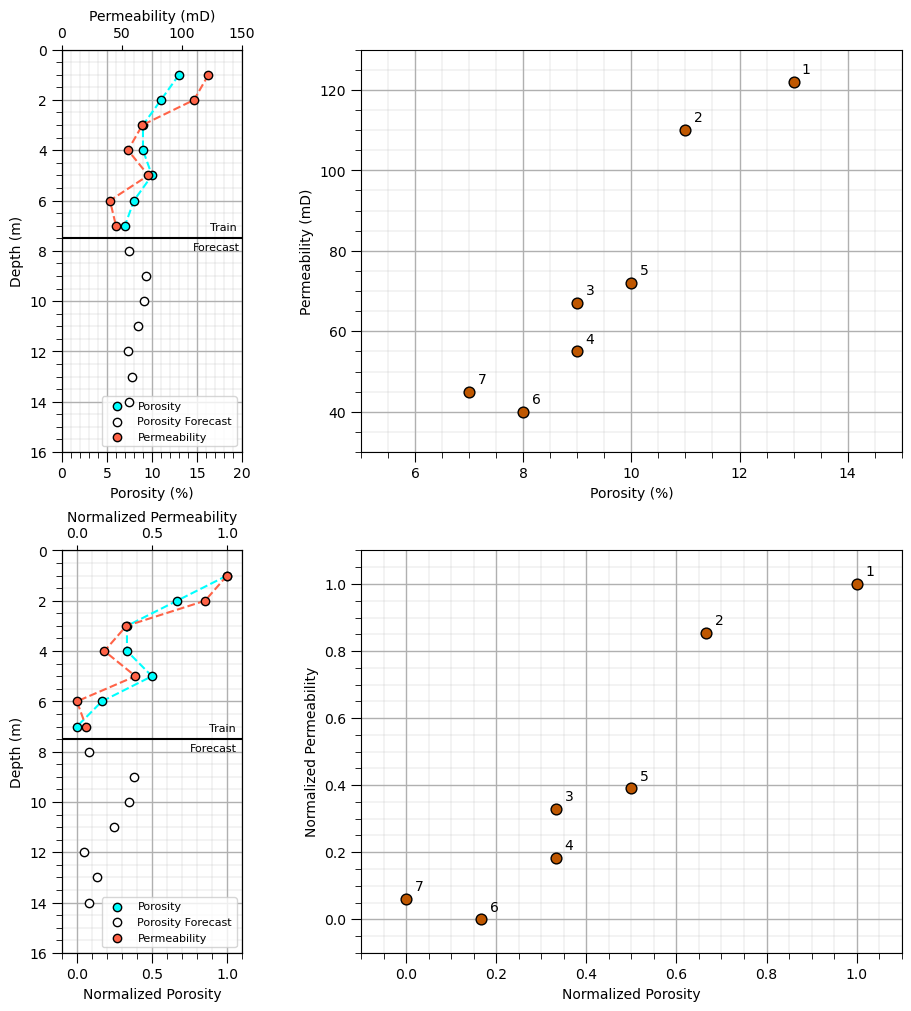

In [16]:
depth = np.arange(1, 8)                                       # training data
porosity = np.array([13.0, 11.0, 9.0, 9.0, 10.0, 8.0, 7.0])
permeability = np.array([122, 110, 67, 55, 72, 40, 45])

depth_forecast = np.arange(8, 15)                             # forecast data: porosity available, permeability unknown
porosity_forecast = np.array([7.5, 9.3, 9.1, 8.5, 7.3, 7.8, 7.5])

pormin, pormax = porosity.min(), porosity.max()               # normalize using training data only
permmin, permmax = permeability.min(), permeability.max()

x = ((porosity - pormin) / (pormax - pormin)).reshape(-1, 1)
y = ((permeability - permmin) / (permmax - permmin)).reshape(-1, 1)

x_forecast = ((porosity_forecast - pormin) / (pormax - pormin)).reshape(-1, 1)

depth_all = np.concatenate([depth, depth_forecast])
x_all = np.concatenate([x, x_forecast])

fig = plt.figure(figsize=(9, 10), constrained_layout=True)    # plot the data
gs = fig.add_gridspec(nrows=2,ncols=2,width_ratios=[1, 3],wspace=0.1)
ax1 = fig.add_subplot(gs[0, 0]); ax3 = fig.add_subplot(gs[0, 1])
ax4 = fig.add_subplot(gs[1, 0]); ax6 = fig.add_subplot(gs[1, 1])

ax1.scatter(porosity,depth,color='aqua',edgecolor='black',label='Porosity',zorder=10) # porosity train
ax1.scatter(porosity_forecast,depth_forecast,color='white',edgecolor='black',label='Porosity Forecast',zorder=10)
ax1.plot(porosity,depth,color='aqua',ls='--',zorder=1); add_grid2(ax1)
ax1.set_ylabel("Depth (m)"); ax1.set_xlabel('Porosity (%)'); ax1.set_xlim([0,20]);
ax1.plot([0,20],[7.5,7.5],color='black'); ax1.text(16.4,7.2,'Train',fontsize=8); ax1.text(14.5,8.0,'Forecast',fontsize=8)

ax2 = ax1.twiny()                                             # second x-axis for permeability
ax2.scatter(permeability,depth,color='tomato',edgecolor='black',label='Permeability',zorder=10) # permeability train
ax2.plot(permeability,depth,color='tomato',ls='--',zorder=1)
ax2.set_xlabel('Permeability (mD)'); ax2.set_ylim([16,0]); ax2.set_xlim([0,150]);

lines1, labels1 = ax1.get_legend_handles_labels(); lines2, labels2 = ax2.get_legend_handles_labels() # combine legends from both x-axes
ax1.legend(lines1 + lines2,labels1 + labels2,fontsize=8,loc='lower right')

ax3.scatter(porosity,permeability,color=color,edgecolor='black',s=60) # porosity vs. permeability scatter plot

for p, k, d in zip(porosity, permeability, depth):            # label points with depth
    ax3.annotate(f'{d}',(p, k),xytext=(6, 6),textcoords='offset points')
ax3.set_xlabel('Porosity (%)');ax3.set_ylabel('Permeability (mD)'); add_grid2(ax3)
ax3.set_xlim([5,15]); ax3.set_ylim([30,130])

ax4.scatter(x,depth,color='aqua',edgecolor='black',label='Porosity',zorder=10)
ax4.scatter(x_forecast,depth_forecast,color='white',edgecolor='black',label='Porosity Forecast',zorder=10)
ax4.plot(x,depth,color='aqua',ls='--',zorder=1); add_grid2(ax4)
ax4.set_ylabel("Depth (m)"); ax4.set_xlabel('Normalized Porosity'); ax4.set_xlim([-0.1,1.1]);

ax5 = ax4.twiny()                                             # second x-axis for permeability
ax5.scatter(y,depth,color='tomato',edgecolor='black',label='Permeability',zorder=10)
ax5.plot(y,depth,color='tomato',ls='--',zorder=1)
ax5.set_xlabel('Normalized Permeability'); ax5.set_ylim([16,0]); ax5.set_xlim([-0.1,1.1]);

lines4, labels4 = ax4.get_legend_handles_labels(); lines5, labels5 = ax5.get_legend_handles_labels() # combine legends from both x-axes

ax4.legend(lines4 + lines5,labels4 + labels5,fontsize=8,loc='lower right')

ax6.scatter(x,y,color=color,edgecolor='black',s=60)           # porosity vs. permeability scatter plot

for p, k, d in zip(x, y, depth):                              # label points with depth
    ax6.annotate(f'{d}',(p, k),xytext=(6, 6),textcoords='offset points')
ax6.set_xlabel('Normalized Porosity'); ax6.set_ylabel('Normalized Permeability'); add_grid2(ax6)
ax6.set_xlim([-0.1,1.1]); ax6.set_ylim([-0.1,1.1])

ax4.plot([-0.1,1.1],[7.5,7.5],color='black'); ax4.text(0.88,7.2,'Train',fontsize=8); ax4.text(0.75,8.0,'Forecast',fontsize=8)
plt.show()

#### Check Positional Embeddings 

Since positional embeddings are fixed, we can visualize them before training the model.

* model dimenison is $d_{model} = 4$, so we need 4 positional embeddings

* we assume wavelenths of $2 \times \pi$ and $20 \times \pi$ for high and low frequency enbeddings respectively each with cosine and sine pairs.


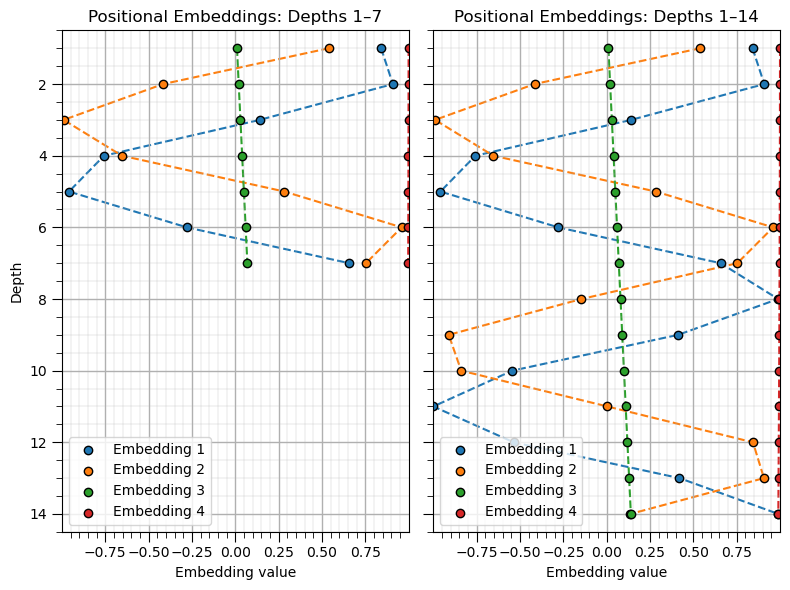

In [17]:
P_train = positional_encoding(depth); P_all = positional_encoding(depth_all)

fig, ax = plt.subplots(1, 2, figsize=(8, 6), sharey=True)

x_min = min(P_train.min(), P_all.min())                       # same x-axis limits for all embedding components
x_max = max(P_train.max(), P_all.max())

for i in range(P_train.shape[1]):                             # left: positional embeddings for training depths 1–7
    ax[0].scatter(P_train[:, i], depth,marker='o',edgecolor='black', label=f'Embedding {i+1}')
    ax[0].plot(P_train[:, i], depth,ls='--',zorder=0)

ax[0].set_title("Positional Embeddings: Depths 1–7"); ax[0].set_xlabel("Embedding value"); ax[0].set_ylabel("Depth")
ax[0].set_xlim(x_min, x_max); ax[0].set_ylim(14.5, 0.5); ax[0].legend(loc='lower left'); add_grid2(ax[0])

for i in range(P_all.shape[1]):                               # right: positional embeddings for all depths 1–14
    ax[1].scatter(P_all[:, i], depth_all,marker='o',edgecolor='black', label=f'Embedding {i+1}')
    ax[1].plot(P_all[:, i], depth_all,ls='--',zorder=0)

ax[1].set_title("Positional Embeddings: Depths 1–14"); ax[1].set_xlabel("Embedding value"); ax[1].set_xlim(x_min, x_max)
ax[1].legend(loc='lower left'); add_grid2(ax[1])

plt.tight_layout(); plt.show()

How do we specify positional embeddings?

1. Use prior knowledge. Choose wavelengths that span meaningful scales in the sequence, such as layer thicknesses or expected correlation ranges.

2. Use a geometric schedule. Cover a range from short to long wavelengths.

3. Tune the positional embeddings using validation data. Compare candidate schedules using a proper holdout or cross-validation procedure.

4. Learn the frequencies. Make frequencies trainable, or use learned positional embeddings. Fourier-feature research also explores task-specific frequency selection for regression problems. 

One important caveat: 

* more wavelengths do not automatically mean better predictions. They increase the positional information available to the model, but with only seven training samples, a richer encoding can also make learning less stable or encourage overfitting.

Summary table of methods for poistional embedding:

| Method | How scales / wavelengths are selected | Main idea |
|---|---|---|
| Original Transformer sinusoidal encoding | Fixed geometric progression of wavelengths | Cover a broad range of positional scales |
| Task-specific sinusoidal encoding | Choose wavelengths based on sequence length or domain knowledge | Match positional scales to the application |
| Learned positional embeddings | Learn a vector for each position during training | Let the model adapt positional representations to the training data |
| Rotary positional embeddings (RoPE) | Use multiple rotation frequencies, typically following a fixed schedule | Encode relative positional offsets through rotations |
| Fourier features | Choose or learn frequencies, sometimes randomly | Represent variation across multiple scales |
| Validation-based selection | Compare candidate wavelength schedules using validation data | Select scales based on predictive performance |
| Domain-informed selection | Use meaningful physical scales, such as layer thicknesses or correlation ranges | Connect positional encoding to the underlying application |

#### Initialize the Weights and Biases

Prior to training the transformer we initialize the weeights and biases to small random values. Here's a summary table of our transformer's trainable model parameters:

| Notation | Description |
|---|---|
| $W_e, b_e$ | Input embedding weights and bias |
| $W_Q, b_Q$ | Query projection weights and bias |
| $W_K, b_K$ | Key projection weights and bias |
| $W_V, b_V$ | Value projection weights and bias |
| $\gamma_1, \beta_1$ | First layer normalization scale and shift |
| $W_1, b_1$ | Feed-forward neural network first layer weights and bias |
| $W_2, b_2$ | Feed-forward neural network second layer weights and bias |
| $\gamma_2, \beta_2$ | Second layer normalization scale and shift |
| $W_y, b_y$ | Output prediction weights and bias |


In [18]:
np.random.seed(42)                                            # set random seed for repeatable results

d_model = 4                                                   # specify model size
d_k = 4
d_ff = 16

W_e = np.random.randn(1, d_model) * 0.1                       # input embedding: 1 porosity value -> 4 values
b_e = np.zeros(d_model)

W_Q = np.random.randn(d_model, d_k) * 0.1                     # query, key, and value transformations
W_K = np.random.randn(d_model, d_k) * 0.1
W_V = np.random.randn(d_model, d_model) * 0.1

b_Q = np.zeros(d_k)
b_K = np.zeros(d_k)
b_V = np.zeros(d_model)

W_1 = np.random.randn(d_model, d_ff) * 0.1                    # feed-forward network
b_1 = np.zeros(d_ff)

W_2 = np.random.randn(d_ff, d_model) * 0.1
b_2 = np.zeros(d_model)
  
W_y = np.random.randn(d_model, 1) * 0.1                       # output layer: 4 values -> 1 permeability prediction
b_y = np.zeros(1)

gamma_1 = np.ones(d_model)                                    # layer normalization parameters
beta_1 = np.zeros(d_model) 
gamma_2 = np.ones(d_model)
beta_2 = np.zeros(d_model)

#### Train the First Transformer

Now we are ready to train the transformer.

* 30,000 training epochs at a learning rate of 0.01 are more than enough

This should run in 10 - 20 seconds.

Epoch    0 | MSE: 0.151969
Epoch 2000 | MSE: 0.006728
Epoch 4000 | MSE: 0.005706
Epoch 6000 | MSE: 0.004918
Epoch 8000 | MSE: 0.003601
Epoch 10000 | MSE: 0.001420
Epoch 12000 | MSE: 0.000189
Epoch 14000 | MSE: 0.000011
Epoch 16000 | MSE: 0.000000
Epoch 18000 | MSE: 0.000000
Epoch 20000 | MSE: 0.000000
Epoch 22000 | MSE: 0.000000
Epoch 24000 | MSE: 0.000000
Epoch 26000 | MSE: 0.000000
Epoch 28000 | MSE: 0.000000


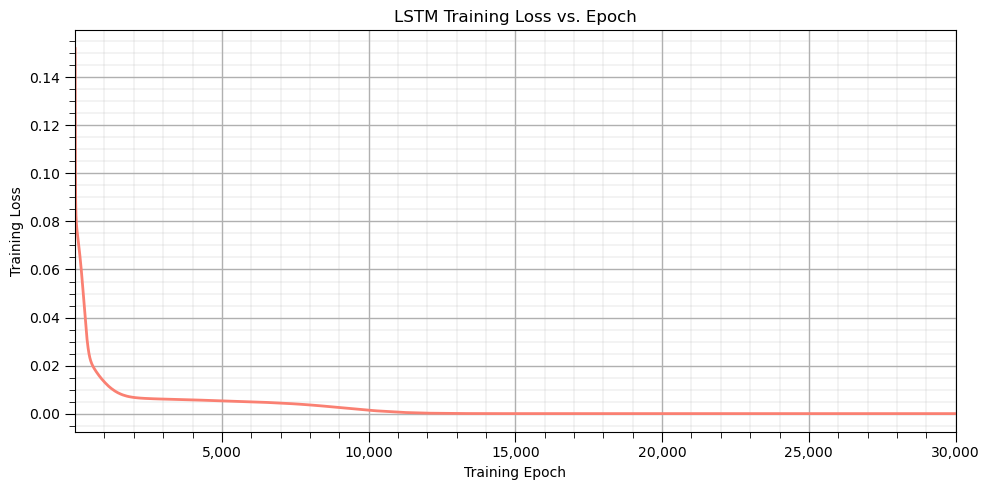

In [19]:
positions_train = np.arange(1, 8)                             # position indices

loss_history = train_transformer(x=x,positions=positions_train,y=y,epochs=30000,learning_rate=0.01,print_every=2000) # train the transformer

plt.figure(figsize=(10, 5))                                   # plot training loss vs. training epoch
iterations = np.arange(1, len(loss_history) + 1)

plt.plot(iterations, loss_history, color='salmon', linewidth=2)
plt.xlabel('Training Epoch'); plt.ylabel('Training Loss'); plt.title('LSTM Training Loss vs. Epoch')
plt.xlim(1, len(loss_history))
plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{x:,.0f}'))
add_grid()

plt.tight_layout(); plt.show()

#### Predict Over Training Interval

Depth 1: observed = 122.0, predicted = 122.0
Depth 2: observed = 110.0, predicted = 110.0
Depth 3: observed = 67.0, predicted = 67.0
Depth 4: observed = 55.0, predicted = 55.0
Depth 5: observed = 72.0, predicted = 72.0
Depth 6: observed = 40.0, predicted = 40.0
Depth 7: observed = 45.0, predicted = 45.0


(30.0, 130.0)

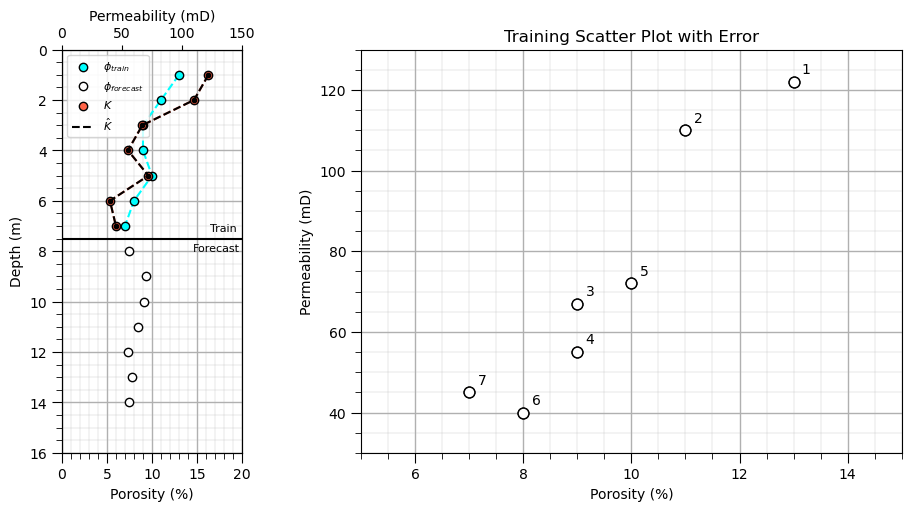

In [20]:
y_hat, A = transformer_forward(x, positions_train)            # predict over training cases

perm_hat = (y_hat.flatten() * (permmax - permmin) + permmin)  # reverse min max normalization
perm_observed = (y.flatten() * (permmax - permmin) + permmin)

for d, observed, predicted in zip(positions_train, perm_observed, perm_hat): # print training data and predictions at training
    print(
        f"Depth {d}: observed = {observed:.1f}, "
        f"predicted = {predicted:.1f}"
    )

fig = plt.figure(figsize=(9, 5), constrained_layout=True)     # figure and GridSpec

gs = fig.add_gridspec(nrows=1,ncols=2,width_ratios=[1, 3],wspace=0.1)

ax1 = fig.add_subplot(gs[0, 0]); ax3 = fig.add_subplot(gs[0, 1])

ax1.scatter(porosity,depth,color='aqua',edgecolor='black',label=r'$\phi_{train}$',zorder=10)
ax1.scatter(porosity_forecast,depth_forecast,color='white',edgecolor='black',label=r'$\phi_{forecast}$',zorder=10)
ax1.plot(porosity,depth,color='aqua',ls='--',zorder=1); add_grid2(ax1)
ax1.set_ylabel("Depth (m)"); ax1.set_xlabel('Porosity (%)'); ax1.set_xlim([0,20]);

ax2 = ax1.twiny()                                             # second x-axis for permeability
ax2.scatter(perm_observed,depth,color='tomato',edgecolor='black',label=r'$K$',zorder=10)
ax2.plot(perm_observed,depth,color='tomato',ls='--',zorder=1)
ax2.set_xlabel('Permeability (mD)'); ax2.set_ylim([16,0]); ax2.set_xlim([0,150]);

ax2.plot(perm_hat,depth,color='black',ls='--',label=r'$\hat{K}$',zorder=100)
ax2.scatter(perm_hat,depth,color='black',s=10,zorder=100)

lines1, labels1 = ax1.get_legend_handles_labels(); lines2, labels2 = ax2.get_legend_handles_labels() # combine legends from both x-axes

ax1.legend(lines1 + lines2,labels1 + labels2,fontsize=8,loc='upper left')

ax1.plot([0,20],[7.5,7.5],color='black'); ax1.text(16.4,7.2,'Train',fontsize=8); ax1.text(14.5,8.0,'Forecast',fontsize=8)

ax3.set_title("Training Scatter Plot with Error")
ax3.scatter(porosity,perm_observed,color=color,edgecolor='black',s=60) # porosity vs. permeability scatter plot
ax3.scatter(porosity,perm_hat,color='white',edgecolor='black',s=60) 

for t in range(len(x)):
    ax3.plot([porosity[t],porosity[t]],[perm_observed[t],perm_hat[t]],color='grey',ls='--',zorder=0)

for p, k, d in zip(porosity, permeability, depth):            # label points with depth
    ax3.annotate(f'{d}',(p, k),xytext=(6, 6),textcoords='offset points')
ax3.set_xlabel('Porosity (%)'); ax3.set_ylabel('Permeability (mD)'); add_grid2(ax3)
ax3.set_xlim([5,15]); ax3.set_ylim([30,130])

#### Predict Over Train and Forecast Intervals

Prediction shape: (14, 1)
Attention shape: (14, 14)
Depth 8: porosity = 1.0, predicted permeability = 123.7
Depth 9: porosity = 2.0, predicted permeability = 112.1
Depth 10: porosity = 3.0, predicted permeability = 68.5
Depth 11: porosity = 4.0, predicted permeability = 56.1
Depth 12: porosity = 5.0, predicted permeability = 72.8
Depth 13: porosity = 6.0, predicted permeability = 41.7
Depth 14: porosity = 7.0, predicted permeability = 47.8


(30.0, 130.0)

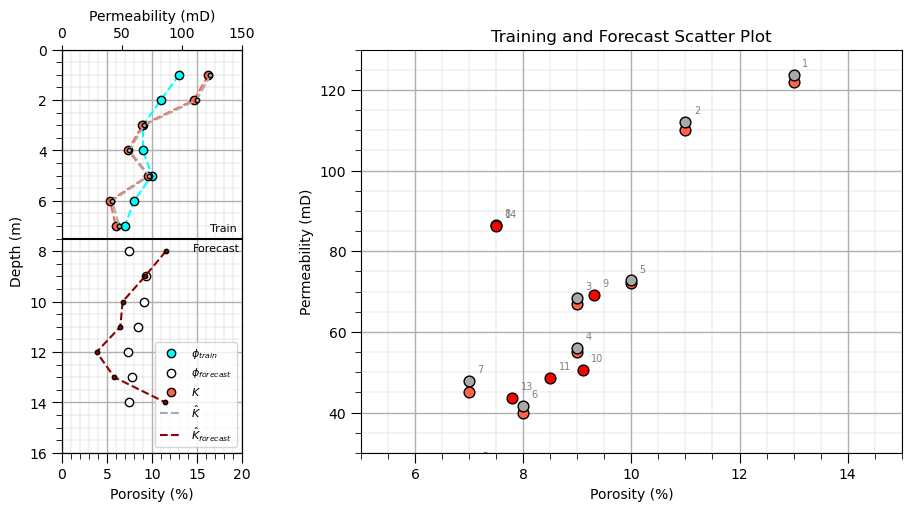

In [21]:
x_all = np.concatenate([x, x_forecast], axis=0)               # concatenate training and forecast inputs
porosity_all = np.concatenate([porosity, porosity_forecast], axis=0)
depth_all = np.concatenate([depth, depth_forecast], axis=0)

positions_all = np.concatenate([depth, depth_forecast])

y_hat_all, A_all = transformer_forward(x_all, positions_all)  # predict normalized permeability at all 14 depths

perm_hat_forecast_all = (y_hat_all.flatten() * (permmax - permmin) + permmin) # convert predictions back to original permeability units

print("Prediction shape:", y_hat_all.shape); print("Attention shape:", A_all.shape)

for d, por, predicted in zip(depth_forecast, depth_all, perm_hat_forecast_all):
    print(
        f"Depth {d}: porosity = {por:.1f}, "
        f"predicted permeability = {predicted:.1f}"
    )

fig = plt.figure(figsize=(9, 5), constrained_layout=True)     # figure and GridSpec
suppress_warnings = True                                      # toggle to supress warnings
gs = fig.add_gridspec(nrows=1,ncols=2,width_ratios=[1, 3],wspace=0.1)

ax1 = fig.add_subplot(gs[0, 0]); ax3 = fig.add_subplot(gs[0, 1])

ax1.scatter(porosity,depth,color='aqua',edgecolor='black',label=r'$\phi_{train}$',zorder=10)
ax1.scatter(porosity_forecast,depth_forecast,color='white',edgecolor='black',label=r'$\phi_{forecast}$',zorder=10)
ax1.plot(porosity,depth,color='aqua',ls='--',zorder=1); add_grid2(ax1)
ax1.set_ylabel("Depth (m)"); ax1.set_xlabel('Porosity (%)'); ax1.set_xlim([0,20]);

ax2 = ax1.twiny()                                             # second x-axis for permeability
ax2.scatter(perm_observed,depth,color='tomato',edgecolor='black',label=r'$K$',zorder=10)
ax2.plot(perm_observed,depth,color='tomato',ls='--',zorder=1)
ax2.set_xlabel('Permeability (mD)'); ax2.set_ylim([16,0]); ax2.set_xlim([0,150]);

ax2.plot(perm_hat_forecast_all[:7],depth_all[:7],color='darkgrey',ls='--',label=r'$\hat{K}$',zorder=100)
ax2.scatter(perm_hat_forecast_all[:7],depth_all[:7],color='darkgrey',edgecolor='black',s=10,zorder=100)
ax2.plot(perm_hat_forecast_all[7:],depth_all[7:],color='darkred',ls='--',label=r'$\hat{K}_{forecast}$',zorder=100)
ax2.scatter(perm_hat_forecast_all[7:],depth_all[7:],color='darkred',edgecolor='black',s=10,zorder=100)

lines1, labels1 = ax1.get_legend_handles_labels(); lines2, labels2 = ax2.get_legend_handles_labels() # combine legends from both x-axes

ax1.legend(lines1 + lines2,labels1 + labels2,fontsize=8,loc='lower right')

ax1.plot([0,20],[7.5,7.5],color='black'); ax1.text(16.4,7.2,'Train',fontsize=8); ax1.text(14.5,8.0,'Forecast',fontsize=8)

ax3.set_title("Training and Forecast Scatter Plot")
ax3.scatter(porosity,permeability,color='tomato',edgecolor='black',s=60) # porosity vs. permeability scatter plot
ax3.scatter(porosity_all[:8],perm_hat_forecast_all[:8],color='darkgrey',edgecolor='black',s=60,label='train') 
ax3.scatter(porosity_all[8:],perm_hat_forecast_all[8:],color='red',edgecolor='black',s=60,label='test') 

for p, k, d in zip(porosity_all, perm_hat_forecast_all, depth_all): # label points with depth
    ax3.annotate(f'{d}',(p, k),xytext=(6, 6),fontsize=7,color='grey',textcoords='offset points')

ax3.set_xlabel('Porosity (%)'); ax3.set_ylabel('Permeability (mD)'); add_grid2(ax3)
ax3.set_xlim([5,15]); ax3.set_ylim([30,130])

#### Check Learned Input Embeddings



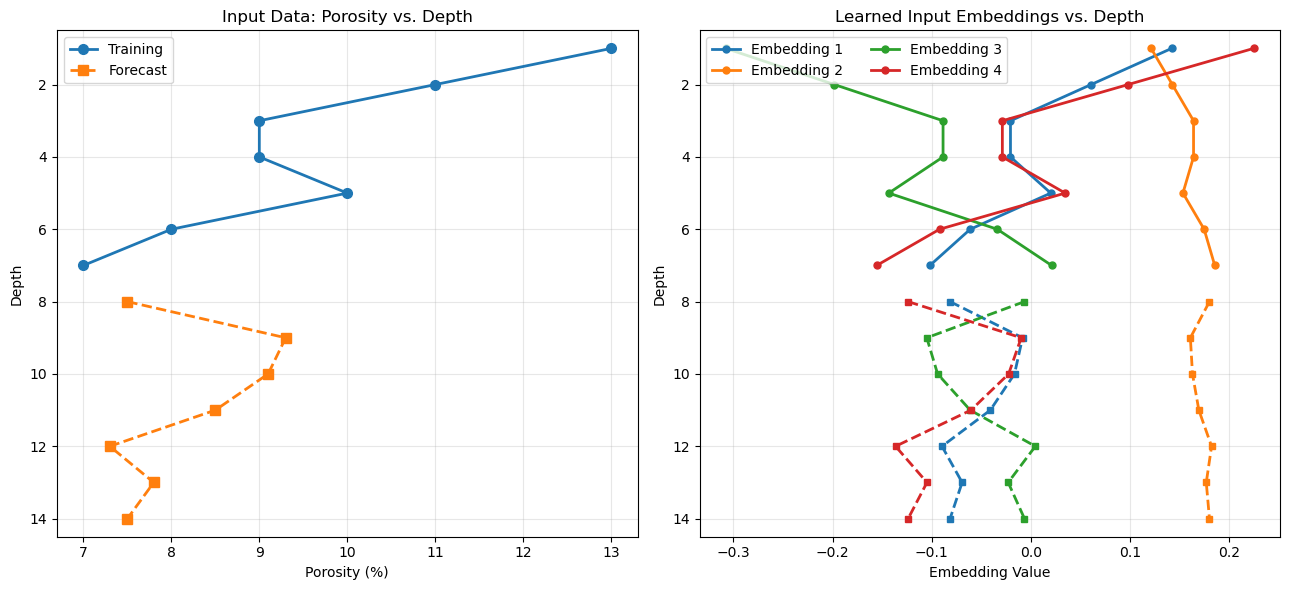

In [22]:
input_embeddings = input_embedding(x)                         # calculate input embeddings
input_embeddings_forecast = input_embedding(x_forecast)

depth_all = np.concatenate([depth, depth_forecast])           # combine training and forecast data
porosity_all = np.concatenate([porosity, porosity_forecast])
input_embeddings_all = np.vstack([
    input_embeddings,
    input_embeddings_forecast
])

fig = plt.figure(figsize=(13, 6))                             # plot porosity and input embeddings

plt.subplot(121)                                              # left: porosity vs. depth
plt.plot(porosity, depth, 'o-', label='Training', 
         color='tab:blue', linewidth=2, markersize=7)
plt.plot(porosity_forecast, depth_forecast, 's--',
         label='Forecast', color='tab:orange', 
         linewidth=2, markersize=7)

plt.xlabel('Porosity (%)'); plt.ylabel('Depth'); plt.title('Input Data: Porosity vs. Depth'); plt.ylim(14.5, 0.5)
plt.grid(alpha=0.3); plt.legend()

plt.subplot(122)                                              # right: input embeddings vs. depth
for i in range(input_embeddings_all.shape[1]):
    plt.plot(input_embeddings_all[:len(depth), i], depth,
             'o-', label=f'Embedding {i+1}',
             linewidth=2, markersize=5)
    plt.plot(input_embeddings_all[len(depth):, i], depth_forecast,
             's--', color=plt.gca().lines[-1].get_color(),
             linewidth=2, markersize=5)

plt.xlabel('Embedding Value'); plt.ylabel('Depth'); plt.title('Learned Input Embeddings vs. Depth'); plt.ylim(14.5, 0.5)
plt.grid(alpha=0.3); plt.legend(ncol=2)

plt.tight_layout(); plt.show()


- Left: Shows the original porosity observations and forecast inputs.
- Right: Shows how the trained linear transformation maps porosity into four embedding components.
- Matching line styles: Solid circles represent training data; dashed squares represent forecast data. Each embedding retains its own color.
The key observation is that, with one input feature, each embedding component is an affine function of normalized porosity. The learned weights and biases determine the scale and offset of each component.

One subtle but important point: the forecast embeddings use the same trained weights and biases as the training embeddings. They are not separately fitted.

#### Check Combined Embeddings 

positional and input embeddings combined



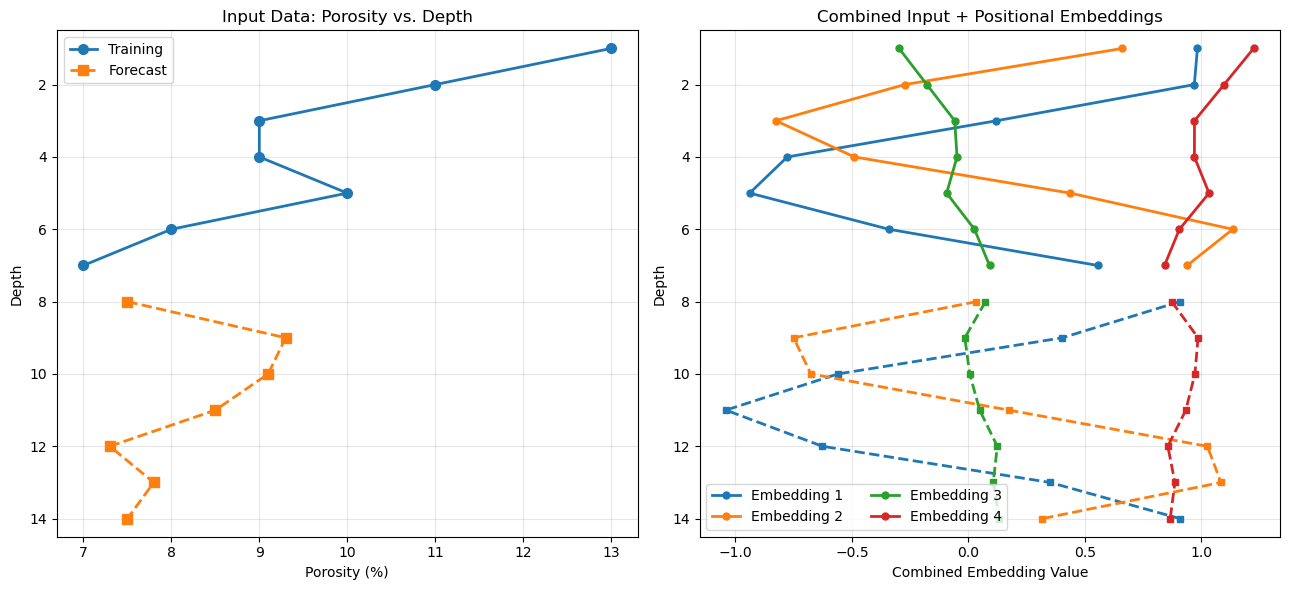

In [23]:
e_t = input_embedding(x)                                      # input, positional and combined embeddings
p_t = positional_encoding(positions_train)
z_t = combine_embeddings(e_t, p_t)

e_t_forecast = input_embedding(x_forecast)
p_t_forecast = positional_encoding(depth_forecast)
z_t_forecast = combine_embeddings(e_t_forecast, p_t_forecast)

z_t_all = np.vstack([z_t, z_t_forecast])                      # combine training and forecast embeddings

porosity_all = np.concatenate([porosity, porosity_forecast])  # combine porosity and depth
depth_all = np.concatenate([depth, depth_forecast])

plt.figure(figsize=(13, 6))                                           

plt.subplot(121)                                              # left: porosity vs. depth
plt.plot(porosity, depth, 'o-', color='tab:blue',label='Training', linewidth=2, markersize=7)
plt.plot(porosity_forecast, depth_forecast, 's--',color='tab:orange', label='Forecast',linewidth=2, markersize=7)

plt.xlabel('Porosity (%)'); plt.ylabel('Depth'); plt.title('Input Data: Porosity vs. Depth'); plt.ylim(14.5, 0.5)
plt.grid(alpha=0.3); plt.legend()

plt.subplot(122)                                              # right: combined embeddings vs. depth
for i in range(z_t_all.shape[1]):
    plt.plot(z_t[:, i], depth, 'o-',
             label=f'Embedding {i+1}',
             linewidth=2, markersize=5)

    plt.plot(z_t_forecast[:, i], depth_forecast, 's--',
             color=plt.gca().lines[-1].get_color(),
             linewidth=2, markersize=5)

plt.xlabel('Combined Embedding Value'); plt.ylabel('Depth'); plt.title('Combined Input + Positional Embeddings')
plt.ylim(14.5, 0.5); plt.grid(alpha=0.3); plt.legend(ncol=2)

plt.tight_layout(); plt.show()

Unlike the input embeddings alone, the combined embeddings reflect both the porosity values and the depth positions. Even if two samples have similar porosity, their combined embeddings can differ because their positional encodings differ.

Note, the positional encodings are fixed, while the input embeddings are learned. Their elementwise sum, $z_t=e_t+p_t$, is what enters the transformer block.

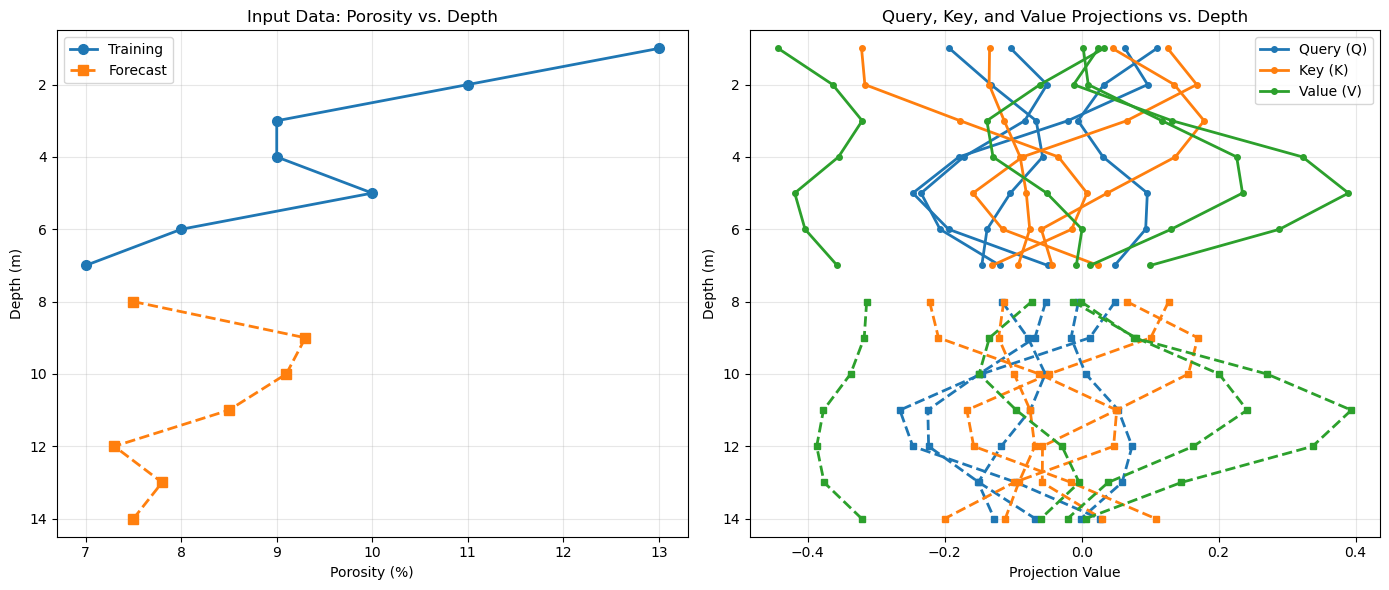

In [41]:
Q, K, V = calculate_QKV(z_t)                                  # calculate query, key, and value projections
Q_forecast, K_forecast, V_forecast = calculate_QKV(z_t_forecast)

depth_all = np.concatenate([depth, depth_forecast])           # combine training and forecast data
porosity_all = np.concatenate([porosity, porosity_forecast])

Q_all = np.vstack([Q, Q_forecast])
K_all = np.vstack([K, K_forecast])
V_all = np.vstack([V, V_forecast])

fig = plt.figure(figsize=(14, 6))                             # plot porosity and Q, K, V projections

plt.subplot(121)                                              # left: porosity vs. depth (keep original plot)
plt.plot(porosity, depth, 'o-', label='Training',color='tab:blue', linewidth=2, markersize=7)
plt.plot(porosity_forecast, depth_forecast, 's--',label='Forecast', color='tab:orange',linewidth=2, markersize=7)

plt.xlabel('Porosity (%)'); plt.ylabel('Depth (m)'); plt.title('Input Data: Porosity vs. Depth'); plt.ylim(14.5, 0.5)
plt.grid(alpha=0.3); plt.legend()
 
ax = plt.subplot(122)                                         # right: Query, Key, and Value projections vs. depth

projections = [
    (Q_all, 'tab:blue', 'Query (Q)'),
    (K_all, 'tab:orange', 'Key (K)'),
    (V_all, 'tab:green', 'Value (V)')
]

n_train = len(depth)

for matrix, color, label in projections:
    for i in range(matrix.shape[1]):
        ax.plot(matrix[:n_train, i], depth, 'o-',             # training: solid line
                color=color, linewidth=2, markersize=4,
                label=label if i == 0 else '_nolegend_')

        ax.plot(matrix[n_train:, i], depth_forecast, 's--',   # forecast: dashed line
                color=color, linewidth=2, markersize=5,
                label='_nolegend_')

ax.set_xlabel('Projection Value'); ax.set_ylabel('Depth (m)'); ax.set_title('Query, Key, and Value Projections vs. Depth')
ax.set_ylim(14.5, 0.5); ax.grid(alpha=0.3); ax.legend()

plt.tight_layout(); plt.show()

#### Plot self-attention weights

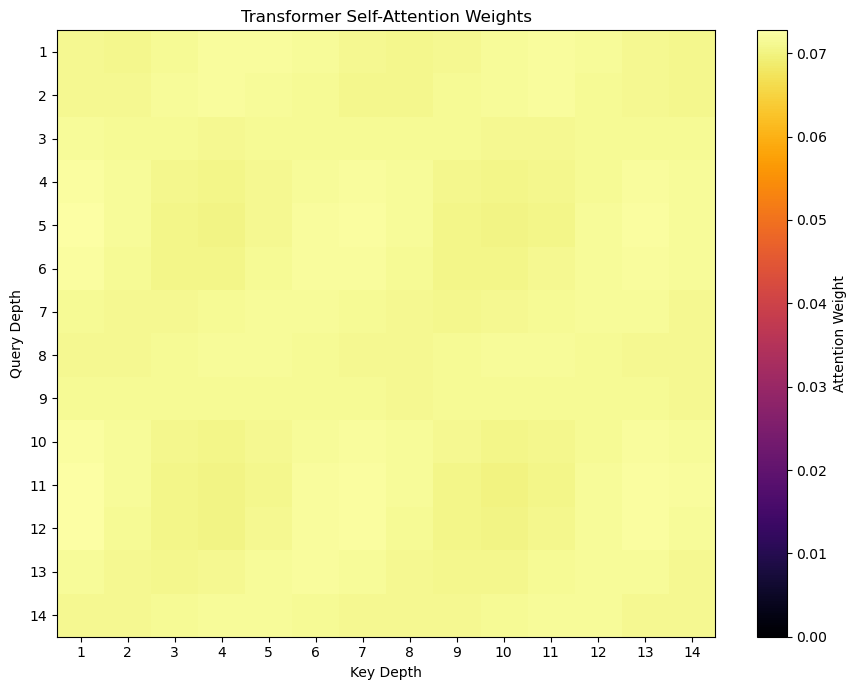

In [42]:
plt.figure(figsize=(9, 7))

plt.imshow(A_all, cmap='inferno', aspect='auto', vmin=0.0, vmax=A_all.max()) # attention weights heat map
plt.colorbar(label='Attention Weight'); plt.xlabel('Key Depth'); plt.ylabel('Query Depth'); plt.title('Transformer Self-Attention Weights')
plt.xticks(np.arange(14), positions_all); plt.yticks(np.arange(14), positions_all)

plt.tight_layout(); plt.show()

What does this mean? The attention mechanism is working mathematically. The weights are positive and each row sums to approximately one.

* Attention is not strongly selective. The query and key vectors produce similar compatibility scores across positions.

* The model still learns. The feedforward network, residual connections, layer normalization, and output layer can all contribute to prediction performance, even when attention weights are nearly uniform.

One subtle point: nearly uniform weights do not necessarily mean the attention output is uninformative. The value vectors $V$ may differ substantially, so their weighted average can still carry useful information.

#### Calculate Intermediate Representations using Trained Model Parameters

In [44]:
Q, K, V = calculate_QKV(z_t_all)                              # self-attention
S = calculate_scores(Q, K)
A = softmax(S)
U = calculate_attention_output(A, V)

R_residual = z_t_all + U                                      # first residual connection and layer normalization
R = layer_norm(R_residual, gamma_1, beta_1)

G = relu(R @ W_1 + b_1)                                       # feedforward network
F_out = G @ W_2 + b_2

H_residual = R + F_out                                        # second residual connection and layer normalization
H = layer_norm(H_residual, gamma_2, beta_2)

Plot the representations
Each panel shows the four embedding components against depth.

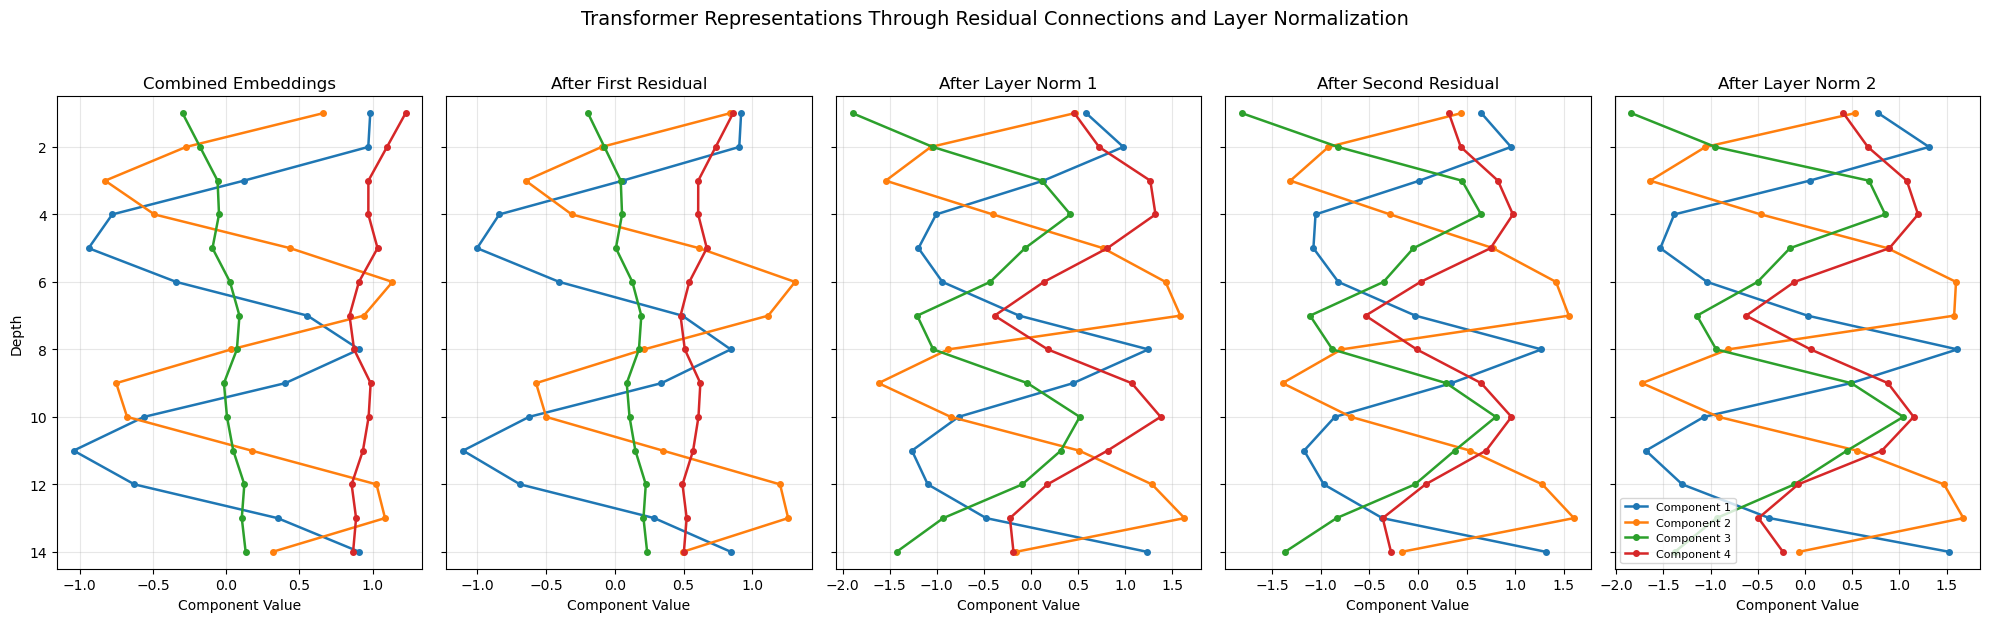

In [45]:
representations = [                                          # representations before and after residual + normalization steps
    (z_t_all, 'Combined Embeddings', 'Input'),
    (R_residual, 'After First Residual', 'Before Layer Norm 1'),
    (R, 'After Layer Norm 1', 'After Layer Norm 1'),
    (H_residual, 'After Second Residual', 'Before Layer Norm 2'),
    (H, 'After Layer Norm 2', 'After Layer Norm 2')
]

fig, axes = plt.subplots(1, 5, figsize=(20, 6), sharey=True)

for ax, (values, title, label) in zip(axes, representations):
    for i in range(values.shape[1]):
        ax.plot(values[:, i], depth_all, 'o-',
                label=f'Component {i+1}', linewidth=1.8,
                markersize=4)

    ax.set_title(title)
    ax.set_xlabel('Component Value')
    ax.set_ylim(14.5, 0.5)
    ax.grid(alpha=0.3)

axes[0].set_ylabel('Depth')
axes[-1].legend(loc='best', fontsize=8)

plt.suptitle('Transformer Representations Through Residual Connections and Layer Normalization',
             y=1.03, fontsize=14)
plt.tight_layout()
plt.show()

What to look for
- Residual connections: The attention output or feedforward output is added to the incoming representation. This lets the block preserve existing information while incorporating a learned update.
- Layer normalization: Each position's feature vector is normalized across its embedding components, then scaled and shifted using learned parameters \(\gamma\) and \(\beta\).
- Representation changes: Compare the relative patterns across depths before and after each operation. Layer normalization changes the component values, but it does not directly mix information between different depths.
One important distinction: the residual addition and layer normalization are separate operations. The first plot helps show the residual update; the second isolates the normalization effect.

Also, because your model has only four embedding components, layer normalization operates over just those four values at each depth. That makes this a compact and useful illustration of the mechanics, although it is a very small representation compared with typical production transformers.

#### Second Transformer Demonstration

The first transformer demonstration was useful, very simple and relatively easy to diagnose.

* a single series with 7 training data and then 7 forecasts

Yet, the somewhat uniform learned attentions were a bit uninteresting. So for this example we make a dataset with a very strong signal that should be learned by self-attention.

* instead of predicting permeability from the porosity at the current depth alone, we construct a target that depends on a particular neighboring depth sample.

For example:

$$
AI_i(t+1) = f(\phi_(t))
$$

Now the model needs information from another position. A successful attention mechanism could learn to emphasize that position through self-attention weights.

Given porosity at seven depths:

$$
\boldsymbol{\phi} = [\phi_1,\phi_2,\ldots,\phi_7]
$$

we calculate the target acoustic impedence so that each prediction depends on the next sample's porosity:

$$
y_i = 2\phi_{i+1} + \epsilon_i
$$

for $i=1,\ldots,6$, where $\epsilon_i$ is small noise random variable. 

This creates a clear hypothesis: when predicting at position $i$, attention should place more weight on position $i+1$.

For example, the desired pattern would look like this:
Illustrative target attention pattern — not a model result

Each row corresponds to a query position; the highlighted key is the next depth sample. The final row needs a separate boundary rule.
This is a useful controlled experiment because you know the dependency in advance and can compare the learned attention matrix against the intended pattern.
3. One important caveat about your current model
Changing the data alone does not guarantee that attention will learn this pattern. Your current architecture has a residual connection and a feed-forward network, and each position's representation contains positional information. Those pathways may still learn the target without relying strongly on attention.

To make the demonstration more realistic and stable:

1. Generate many synthetic sequences rather than training on only seven samples.
   
2. Use varied porosity values and target that genuinely depends on another position.

3. Train on multiple sequences and evaluate on held-out sequences.

4. Plot the attention matrix and measure prediction error when learned attention is replaced by uniform or identity attention.

5. If the model still avoids selective attention, simplify the model or constrain the prediction pathway so that cross-position information is necessary.

#### Generate Second Synthetic Dataset

In [ ]:
X, y = generate_neighbor_dataset(n_sequences=1000,seq_length=7,noise_std=0.01,seed=42) # generate synthetic dataset

rng = np.random.default_rng(42)    # split by sequence, not by individual depth sample
n_sequences = X.shape[0]
indices = rng.permutation(n_sequences)
n_train = int(0.8 * n_sequences)
train_idx = indices[:n_train]
test_idx = indices[n_train:]
X_train, y_train = X[train_idx], y[train_idx]
X_test, y_test = X[test_idx], y[test_idx]

positions = np.arange(1, X.shape[1] + 1)       # seven depth positions, shared by every sequence

print("Training sequences:", X_train.shape)
print("Testing sequences:", X_test.shape)
print("Positions:", positions)

Let's adapt the training procedure to our new dataset: 

* 1,000 independent sequences, each containing seven depth samples.

The goal is to train across many sequences so the transformer can learn the cross-depth relationship, then inspect whether its attention becomes more differentiated.

Comparing this demonstration to our first demonstration:

* **Initialization** - keep the same small transformer architecture and parameter dimensions.
  
* **Training** - iterate over the 1,000 sequences, calculating the loss and gradients for each sequence (or a mini-batch), then update the shared parameters. We must not treat all 7,000 depth samples as one sequence, because that would mix unrelated sequences.

* existing manual gradient function processes a single sequence, therefore, we average the gradients over a mini-batch, provided calculate_gradients(x, positions, y) returns gradients without updating the weights internally.

#### Initialize Transformer Parameters

Once again, prior to training the transformer we initialize the weeights and biases to small random values. Here's a summary table of our transformer's trainable model parameters:

| Notation | Description |
|---|---|
| $W_e, b_e$ | Input embedding weights and bias |
| $W_Q, b_Q$ | Query projection weights and bias |
| $W_K, b_K$ | Key projection weights and bias |
| $W_V, b_V$ | Value projection weights and bias |
| $\gamma_1, \beta_1$ | First layer normalization scale and shift |
| $W_1, b_1$ | Feed-forward neural network first layer weights and bias |
| $W_2, b_2$ | Feed-forward neural network second layer weights and bias |
| $\gamma_2, \beta_2$ | Second layer normalization scale and shift |
| $W_y, b_y$ | Output prediction weights and bias |

In [ ]:
np.random.seed(42)                                            # set random number seed for repeatable training

d_model = 4                                                   # specify model size
d_k = 4
d_ff = 16

W_e = np.random.randn(1, d_model) * 0.1                       # input embedding: 1 porosity value -> 4 values
b_e = np.zeros(d_model)

W_Q = np.random.randn(d_model, d_k) * 0.1                     # query, key, and value transformations
W_K = np.random.randn(d_model, d_k) * 0.1
W_V = np.random.randn(d_model, d_model) * 0.1

b_Q = np.zeros(d_k)
b_K = np.zeros(d_k)
b_V = np.zeros(d_model)

W_1 = np.random.randn(d_model, d_ff) * 0.1                    # feed-forward network
b_1 = np.zeros(d_ff)

W_2 = np.random.randn(d_ff, d_model) * 0.1
b_2 = np.zeros(d_model)

W_y = np.random.randn(d_model, 1) * 0.1                       # output layer: 4 values -> 1 prediction
b_y = np.zeros(1)

gamma_1 = np.ones(d_model)                                    # layer normalization parameters
beta_1 = np.zeros(d_model)

gamma_2 = np.ones(d_model)
beta_2 = np.zeros(d_model)

params = {                                                    # shared parameter dictionary for training
    'W_e': W_e, 'b_e': b_e,
    'W_Q': W_Q, 'W_K': W_K, 'W_V': W_V,
    'b_Q': b_Q, 'b_K': b_K, 'b_V': b_V,
    'W_1': W_1, 'b_1': b_1,
    'W_2': W_2, 'b_2': b_2,
    'W_y': W_y, 'b_y': b_y,
    'gamma_1': gamma_1, 'beta_1': beta_1,
    'gamma_2': gamma_2, 'beta_2': beta_2
}

#### Train the Second Transformer

Train transformer across multiple independent sequences.

* given the increased dataset size this model requires a couple of minutes to train.

In [ ]:
loss_history = train_transformer_sequences(X_train,y_train,positions,epochs=1000,batch_size=32,learning_rate=0.3) # train transformer

In [ ]:
plt.figure(figsize=(10, 5))                                   # plot training loss vs. training epoch
iterations = np.arange(1, len(loss_history) + 1)

plt.plot(iterations, loss_history, color='salmon', linewidth=2)
plt.xlabel('Training Epoch'); plt.ylabel('Training Loss'); plt.title('Transformer Training Loss vs. Epoch')
plt.xlim(1, len(loss_history))
plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{x:,.0f}'))
add_grid()

plt.tight_layout(); plt.show()

#### Visualize Predictions at 9 Random Training Cases

Randomly select 9 training sequences, predict and visualize.

In [ ]:
rng = np.random.default_rng(42)                                # select random training cases
sample_idx = rng.choice(len(X_train), size=9, replace=False)

fig, axes = plt.subplots(3, 3, figsize=(14, 12), sharex=False)

for ax, idx in zip(axes.flat, sample_idx):                     # input and target for this sequence
    x_i = X_train[idx]       # (7, 1)
    y_i = y_train[idx]       # (7, 1)

    y_hat, A = transformer_forward(x_i, positions)             # predict with the trained transformer

    porosity = x_i.ravel()                                     # flatten for plotting
    target = y_i.ravel()
    prediction = np.asarray(y_hat).ravel()
    depth = np.asarray(positions)

    ax.plot(target, depth, color = 'red', ls = '-', label='K') # left axis: target and prediction versus depth
    ax.plot(prediction, depth, color='red',ls = '--', label='$\hat{K}$')

    ax_por = ax.twiny()                                        # twin axis: porosity versus depth
    ax_por.plot(porosity, depth, color = 'black',ls = '-', label='$\phi$')

    ax.set_title(f'Training sequence {idx}')
    ax.set_ylabel('Depth sample')
    ax.invert_yaxis()
    ax.grid(True, alpha=0.3)

    ax.set_xlabel('Permeability (normalized) (target / prediction)')
    ax_por.set_xlabel('Porosity')

    lines1, labels1 = ax.get_legend_handles_labels()           # combine legends from both axes
    lines2, labels2 = ax_por.get_legend_handles_labels()
    ax.legend(lines1 + lines2, labels1 + labels2,
              fontsize=8, loc='best')

plt.tight_layout(); plt.show()

Predictions are often close to training data.


#### Visualize Predictions at 9 Random Test Cases

Now we randomly split testing cases and visualize the data and model predictions.

In [ ]:
rng = np.random.default_rng(42)                                # randomly select 9 test sequences

sample_idx = rng.choice(len(X_test), size=9, replace=False)

fig, axes = plt.subplots(3, 3, figsize=(14, 12), sharex=False)

for ax, idx in zip(axes.flat, sample_idx):                     # input and target for this test sequence
    x_i = X_test[idx]       # (7, 1)                        
    y_i = y_test[idx]       # (7, 1)

    y_hat, A = transformer_forward(x_i, positions)             # predict with the trained transformer

    porosity = x_i.ravel()                                     # flatten for plotting
    target = y_i.ravel()
    prediction = np.asarray(y_hat).ravel()
    depth = np.asarray(positions)

    ax.plot(target, depth, color = 'red', ls = '-', label='K') # left axis: target and prediction versus depth
    ax.plot(prediction, depth, color='red',ls = '--', label='$\hat{K}$')

    ax_por = ax.twiny()                                        # twin axis: porosity versus depth
    ax_por.plot(porosity, depth, color = 'black',ls = '-', label='$\phi$')

    ax.set_title(f'Testing sequence {idx}')
    ax.set_ylabel('Depth sample')
    ax.invert_yaxis()
    ax.grid(True, alpha=0.3)

    ax.set_xlabel('Permeability (normalized) (target / prediction)')
    ax_por.set_xlabel('Porosity')

    lines1, labels1 = ax.get_legend_handles_labels()           # combine legends from both axes
    lines2, labels2 = ax_por.get_legend_handles_labels()
    ax.legend(lines1 + lines2, labels1 + labels2,
              fontsize=8, loc='best')

plt.tight_layout(); plt.show()

#### Visualize Some Embeddings 

Select 9 reproducible sequence-position pairs

In [ ]:
rng = np.random.default_rng(42)                                # select random cases
n_cases = 9
n_sequences, seq_length, _ = X_test.shape

sequence_ids = rng.integers(0, n_sequences, size=n_cases)
position_ids = rng.integers(0, seq_length, size=n_cases)

positions = np.arange(1, seq_length + 1)                       # fixed position encodings for the sequence
P_all = positional_encoding(positions)

fig, axes = plt.subplots(                                      # plot learned embedding, positional encoding, and sum
    3, 3, figsize=(13, 10), sharex=True, sharey=True
)

embedding_dim = P_all.shape[-1]
component_ids = np.arange(1, embedding_dim + 1)

for i, ax in enumerate(axes.flat):
    seq_id = sequence_ids[i]
    pos_id = position_ids[i]

    x_value = X_test[seq_id, pos_id:pos_id + 1, :]

    E = input_embedding(x_value)
    P = P_all[pos_id:pos_id + 1, :]
    Z = combine_embeddings(E, P)

    ax.plot(component_ids, E[0], "o-", label="Input Embedding")
    ax.plot(component_ids, P[0], "s--", label="Positional Embedding")
    ax.plot(component_ids, Z[0], "^-", label="Combined Embedding")

    ax.axhline(0, color="gray", linewidth=0.7, alpha=0.5)

    ax.set_title(
        f"Case {i+1}: sequence {seq_id}, "
        f"depth {pos_id + 1:.1f} m\n"
        f"Porosity = {x_value[0, 0]:.3f}"
    )

    ax.set_ylim(-1.1, 1.1)
    ax.set_xticks(component_ids)
    ax.grid(True, alpha=0.25)

fig.supxlabel("Embedding Index")
fig.supylabel("Embedding")
fig.suptitle(
    "Learned Input Embeddings + Positional Encoding",
    fontsize=15, y = 0.93
)

handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(
    handles, labels,
    loc="lower center", ncol=3,
    bbox_to_anchor=(0.5, 0.035)
)

plt.tight_layout(rect=[0.03, 0.06, 1, 0.94]); plt.show()

#### Plot Learned Attentention Matrix

Now let's visualize the attention weight matrix,

* check if the attention weights have characterized the lag relationship that we designed in the synthetic data.

In [ ]:
_, A = transformer_forward(X_test[0], positions)               # retreive the trained attention weight matrix      

plt.figure(figsize=(9, 7))
plt.imshow(A, cmap='inferno', aspect='auto',vmin=A.min(), vmax=A.max()) # attention weights matrix heatmap

plt.colorbar(label='Attention Weight'); plt.xlabel('Key Depth'); plt.ylabel('Query Depth'); plt.title('Transformer Self-Attention Weights')

plt.xticks(np.arange(7), positions); plt.yticks(np.arange(7), positions)

plt.gca().set_xticks(np.arange(-0.5, 7, 1), minor=True)        # add grid lines between cells
plt.gca().set_yticks(np.arange(-0.5, 7, 1), minor=True)
plt.grid(which='minor', color='white', linestyle='-', linewidth=1.5)

plt.tick_params(which='minor', bottom=False, left=False)

plt.tight_layout(); plt.show()

It is clear above that our trained attention matrix has learned a lag representation in depth for predicting permeability from porosity.

* attention weights for [i, i + 1] are all high.

* notice that this is assymetric, going in only one direction


#### Visualize Value and Output, Attention Weighted Combination of Values

Use the same 9 sequences as the embedding plot

In [ ]:
if "sequence_ids" not in globals():   # assumes sequence_ids, X_test, and positions already exist, if not, create a reproducible selection
    rng = np.random.default_rng(42)
    sequence_ids = rng.choice(len(X_test), size=9, replace=False)

fig, axes = plt.subplots(3, 3, figsize=(14, 10), sharex=True, sharey=True)

depth = np.arange(1, X_test.shape[1] + 1)
component_ids = np.arange(1, d_model + 1)

for i, ax in enumerate(axes.flat):
    seq_id = sequence_ids[i]
    x = X_test[seq_id]

    E = input_embedding(x)                    # forward calculations through the attention sublayer
    P = positional_encoding(positions)
    Z = combine_embeddings(E, P)

    Q, K, V = calculate_QKV(Z)
    S = calculate_scores(Q, K)
    A = softmax(S)
    U = calculate_attention_output(A, V)

    for j in range(d_model):                           # plot all four components across depth
        ax.plot(depth, V[:, j],linestyle="--", marker="o",alpha=0.75,label=f"V component {j+1}" if i == 0 else None)
        ax.plot(depth, U[:, j],linestyle="-", marker="s",alpha=0.9,label=f"U component {j+1}" if i == 0 else None)
    ax.set_title(f"Sequence {seq_id}"); ax.set_xticks(depth); ax.set_xlabel("Depth (m)"); ax.grid(True, alpha=0.25)

fig.supylabel("Component value")
fig.suptitle("Value Vectors and Attention Outputs",fontsize=15,y=0.94)

handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels,loc="lower center", ncol=4,bbox_to_anchor=(0.5, 0.01))

plt.tight_layout(rect=[0.03, 0.08, 1, 0.91]); plt.show()

How to interpret the plot?

* Dashed lines with circles: $V_t$, the value-vector components at each depth.

* Solid lines with squares: $U_t$, the attention-weighted combinations of value vectors.

* Differences between the two: show how attention mixes information from across the sequence.
  
One important detail for your demonstration: each output $U_t$ is a weighted combination of all seven value vectors, not just the value vector at the next depth. The learned attention matrix determines how much each position contributes.


#### Visualize Residual Connections, Layer Normalization, and Feed-forward Outputs

Let’s extend the transformer diagnostic plots to the next stage: residual connections, layer normalization, and feed-forward outputs. We’ll follow the tensors through the block at each depth position and compare how each operation changes the representations.

For our transformer model, we visualize:

* $Z$: input embeddings plus positional encodings

* $U$: attention output

* $T_1 = Z + U$: first residual connection

* $R = \operatorname{LayerNorm}(T_1)$: normalized representation

* $F$: feed-forward network output

* $T_2 = R + F$: second residual connection

* $H = \operatorname{LayerNorm}(T_2)$: final block representation

In [ ]:
if "sequence_ids" not in globals():        # assumes sequence_ids, X_test, and positions already exist, if not, create a reproducible selection:
    rng = np.random.default_rng(42)
    sequence_ids = rng.choice(
        len(X_test), size=9, replace=False
    )

depth = np.arange(1, X_test.shape[1] + 1)
component_ids = np.arange(1, d_model + 1)

stage_names = [                             # five stages to compare
    r"$T_1 = Z + U$",
    r"$R = \mathrm{LayerNorm}(T_1)$",
    r"$F = \mathrm{FFN}(R)$",
    r"$T_2 = R + F$",
    r"$H = \mathrm{LayerNorm}(T_2)$"
]

fig, axes = plt.subplots(5, 3,figsize=(15, 14),sharex=True,sharey="row")

for col, seq_id in enumerate(sequence_ids[:3]):
    pass

for col in range(3):                        # use the same nine sequences across the columns and rows
    for row in range(3):
        seq_id = sequence_ids[row * 3 + col]
        x = X_test[seq_id]

        E = input_embedding(x)                       # input and positional embeddings
        P = positional_encoding(positions)
        Z = combine_embeddings(E, P)

        Q, K, V = calculate_QKV(Z)                      # self-attention
        S = calculate_scores(Q, K)
        A = softmax(S)
        U = calculate_attention_output(A, V)

        T1 = Z + U                                            # first residual connection and layer normalization
        R = layer_norm(T1, gamma_1, beta_1)

        G_pre = R @ W_1 + b_1                                   # feed-forward network
        G = np.maximum(0, G_pre)
        F_out = G @ W_2 + b_2

        T2 = R + F_out                                       # second residual connection and layer normalization
        H = layer_norm(T2, gamma_2, beta_2)

        stages = [T1, R, F_out, T2, H]

        for stage_idx, stage in enumerate(stages):
            ax = axes[stage_idx, col]
            for j in range(d_model):
                ax.plot(depth,stage[:, j],marker="o",linewidth=1.5,markersize=3.5,color=f"C{j}",
                    label=f"Component {j+1}" if col == 0 else None)

            ax.axhline(0, color="gray", linewidth=0.7, alpha=0.5); ax.grid(True, alpha=0.25); ax.set_xticks(depth)

            if col == 0:
                ax.set_ylabel(stage_names[stage_idx])

            if stage_idx == 0:
                ax.set_title(f"Sequence {seq_id}")

            if stage_idx == 4:
                ax.set_xlabel("Depth (m)")

# One shared legend: explicitly keep only unique labels
handles, labels = [], []

for ax in axes.flat:
    h, l = ax.get_legend_handles_labels()
    for handle, label in zip(h, l):
        if label and label not in labels:
            handles.append(handle)
            labels.append(label)

fig.legend(handles,labels,loc="lower center",ncol=d_model,bbox_to_anchor=(0.5, 0.005),frameon=False)

fig.suptitle("Residual Connections, Layer Normalization, and Feed-Forward Outputs",fontsize=15,y=0.995)

plt.tight_layout(rect=[0.02, 0.04, 1, 0.98])
plt.show()


How to read these plots,

* $T_1 \rightarrow R$ - layer normalization rescales and recenters the feature values at each sequence position, subject to the learned scale and shift parameters.

* $F$ - the feed-forward network transforms each position's normalized representation independently. Unlike self-attention, this operation does not directly mix information across positions.

* $R \rightarrow T_2$ - the second residual connection adds the feed-forward output to the existing representation.

* $T_2 \rightarrow H$: The final layer normalization produces the representation passed to the output projection.

Note, the feed-forward output $F$ is not necessarily small, and the residual addition does not guarantee that information is preserved unchanged. These plots let us inspect what actually happens in our trained model rather than assuming it.



#### Comments

This was a basic treatment of transformers, with a simple transfomer built from scratch and applied to 2 simple demonstration problems. Much more could be done and discussed, I have many more resources. Check out my [shared resource inventory](https://michaelpyrcz.com/my-resources) and the YouTube lecture links at the start of this chapter with resource links in the videos' descriptions.

I hope this is helpful,

*Michael*

#### About the Author

<figure style="text-align: center;">
  <img src="_static/intro/michael_pyrcz_officeshot_jacket.jpg" style="display: block; margin: 0 auto; width: 70%;">
  <figcaption style="text-align: center;"> Professor Michael Pyrcz in his office on the 40 acres, campus of The University of Texas at Austin.
</figcaption>
</figure>

Michael Pyrcz is a professor in the [Cockrell School of Engineering](https://cockrell.utexas.edu/faculty-directory/alphabetical/p), and the [Jackson School of Geosciences](https://www.jsg.utexas.edu/researcher/michael_pyrcz/), at [The University of Texas at Austin](https://www.utexas.edu/), where he researches and teaches subsurface, spatial [data analytics](MachineLearning_glossary_d_f.ipynb#data-analytics), [geostatistics](MachineLearning_glossary_g_l.ipynb#geostatistics), and machine learning. Michael is also,

* the principal investigator of the [Energy Analytics](https://fri.cns.utexas.edu/energy-analytics) freshmen research initiative and a [core](MachineLearning_glossary_a_c.ipynb#core) faculty in the Machine Learn Laboratory in the College of Natural Sciences, The University of Texas at Austin

* an associate editor for [Computers and Geosciences](https://www.sciencedirect.com/journal/computers-and-geosciences/about/editorial-board), and a board member for [Mathematical Geosciences](https://link.springer.com/journal/11004/editorial-board), the International Association for Mathematical Geosciences. 

Michael has written over 100 [peer-reviewed publications](https://scholar.google.com/citations?user=QVZ20eQAAAAJ&hl=en), a [Python package](https://pypi.org/project/geostatspy/) for spatial [data](MachineLearning_glossary_d_f.ipynb#data) analytics, co-authored a textbook on spatial data analytics, [Geostatistical Reservoir Modeling](https://www.amazon.com/Geostatistical-Reservoir-Modeling-Michael-Pyrcz/dp/0199731446) and author of two recently released e-books, [Applied Geostatistics in Python: a Hands-on Guide with GeostatsPy](https://geostatsguy.github.io/GeostatsPyDemos_Book/intro.html) and [Applied Machine Learning in Python: a Hands-on Guide with Code](https://geostatsguy.github.io/MachineLearningDemos_Book/intro.html).

All of Michael’s university lectures are available on his [YouTube Channel](https://www.youtube.com/@GeostatsGuyLectures) with links to 100s of Python interactive dashboards and well-documented workflows in over 40 repositories on his [GitHub account](https://github.com/GeostatsGuy), to support any interested students and working professionals with evergreen content. To find out more about Michael’s work and shared educational resources visit his [Website](https://www.michaelpyrcz.com).

#### Want to Work Together?

I hope this content is helpful to those that want to learn more about subsurface modeling, [data analytics](MachineLearning_glossary_d_f.ipynb#data-analytics) and machine learning. Students and working professionals are welcome to participate.

* Want to invite me to visit your company for training, mentoring, project review, workflow design and / or consulting? I'd be happy to drop by and work with you! 

* Interested in partnering, supporting my graduate student research or my Subsurface [Data](MachineLearning_glossary_d_f.ipynb#data) Analytics and Machine Learning consortium (co-PI is Professor John Foster)? My research combines data analytics, stochastic modeling and machine learning theory with practice to develop novel methods and workflows to add [value](MachineLearning_glossary_s_z.ipynb#value). We are solving challenging subsurface problems!

* I can be reached at mpyrcz@austin.utexas.edu.

I'm always happy to discuss,

*Michael*

Michael Pyrcz, Ph.D., P.Eng. Professor, Cockrell School of Engineering and The Jackson School of Geosciences, The University of Texas at Austin

More Resources Available at: [Twitter](https://twitter.com/geostatsguy) | [GitHub](https://github.com/GeostatsGuy) | [Website](http://michaelpyrcz.com) | [GoogleScholar](https://scholar.google.com/citations?user=QVZ20eQAAAAJ&hl=en&oi=ao) | [Geostatistics Book](https://www.amazon.com/Geostatistical-Reservoir-Modeling-Michael-Pyrcz/dp/0199731446) | [YouTube](https://www.youtube.com/channel/UCLqEr-xV-ceHdXXXrTId5ig)  | [Applied Geostats in Python e-book](https://geostatsguy.github.io/GeostatsPyDemos_Book/intro.html) | [Applied Machine Learning in Python e-book](https://geostatsguy.github.io/MachineLearningDemos_Book/) | [LinkedIn](https://www.linkedin.com/in/michael-pyrcz-61a648a1)